<a href="https://colab.research.google.com/github/InverniciMarta/RL_exam_project/blob/main/notebooks/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reinforcement Learning project:
## Adaptive optics control with reinforcement learning

In [ ]:
#Uncomment to run in Colab
# !pip install hcipy
# !pip install --force-reinstall xxhash==3.8.1

### Command line arguments

In [ ]:
import argparse

def create_args():

    parser = argparse.ArgumentParser(description="Adaptive Optics Closed Loop System Initialization and Simulation Parameters")

    # Adaptive Optics system set up
    parser.add_argument("--wavelength_wfs", type=float, default=842.0E-9, help="Wavelength for the wavefront sensor in meters (default: 842 nm)")
    parser.add_argument("--telescope_diameter", type=float, default=6.5, help="Diameter of the telescope in meters (default: 6.5 m)")
    parser.add_argument("--num_pupil_pixels", type=int, default=70, help="Number of pixels across the pupil grid (default: 70)")
    parser.add_argument("--num_actuators_across_pupil", type=int, default=40, help="Number of actuators across the pupil (default: 40)")
    parser.add_argument("--dm_oversampling", type=float, default=1.4, help="Oversampling factor of number of pixels across PWFS single pupil with respect to actuators across dm (default:1.4)")
    parser.add_argument("--rcond", type=float, default=0.08, help="Regularization condition number for Tikhonov inversion (default: 0.08)")
    parser.add_argument("--seeing", type=float, default=0.6, help="Seeing in arcseconds at 500nm (default: 0.6 arcsec)") #the more it grows the smaller r_0
    parser.add_argument("--outer_scale", type=float, default=30, help="Outer scale of turbulence in meters (default: 30 m)")
    parser.add_argument("--tau0", type=float, default=0.005, help="Coherence time of turbulence in seconds (default: 0.005 s)")
    parser.add_argument("--prob_amp_coeff", type=float, default=0.07, help="Coefficient for actuator amplitude probing (default: 0.07)")
    parser.add_argument("--power_cutoff", type=float, default=0.08, help="Power cutoff for illuminated actuators (default: 0.08)")
    parser.add_argument("--modulation_radius", type=int, default=3, help="Radius to modulate modulated pyramid wavefront sensor (default: 3). When 0, WFS is unmodulated")
    parser.add_argument("--modulation_steps", type=int, default=8, help="Iteration steps to modulate pyramid WFS (default: 8)")

    # Calibration of normalisation scales, entropy temperature init
    parser.add_argument("--max_command", type=float, default=5E-6, help="Maximum command for the actuators (default: 5000 nm)")
    parser.add_argument("--coeff_max_action", type=float, default=2, help="Coefficient multiplying reconstruction root mean square to set maximum RL action per actuator")
    parser.add_argument("--calib_steps", type=int, default=300, help="Calibration steps used to measure the RMS of reconstruction/commands (default: 300)")
    parser.add_argument("--calib_burn_in", type=int, default=50, help="Calibration burn-in steps used to measure the RMS of reconstruction/commands (default: 50)")
    parser.add_argument("--calib_n_runs", type=int, default=4, help="Number of runs for calibration (default: 4)")
    parser.add_argument("--alpha_init", type=float, default=0.2, help="Initial SAC temperature alpha (default: 0.2, as in Pou et al.)") # Residual RL correction: start conservatively so SAC cannot undo the integrator.

    # closed loop episode simulation
    parser.add_argument("--gain", type=float, default=0.6, help="Gain for the closed loop control (default: 0.6)")
    parser.add_argument("--leakage", type=float, default=0.01, help="Leakage for the closed loop control (default: 0.01)")
    parser.add_argument("--num_iterations", type=int, default=100, help="Number of iterations for the closed loop simulation (default: 100)") #not used
    parser.add_argument("--burn_in_iterations", type=int, default=5, help="Number of burn-in iterations before accumulating long-exposure image (default: 5)")
    parser.add_argument("--delta_t", type=float, default=1E-3, help="Time step for each iteration in seconds (default: 1E-3 s)")

    # SAC parameters
    parser.add_argument("--gamma", type=float, default=0.3, help="Discount factor for SAC (default: 0.3)")
    parser.add_argument("--tau", type=float, default=0.005, help="Soft update coefficient for target networks in SAC (default: 0.005)")
    parser.add_argument("--replay_pool_size", type=int, default=5000, help="Size of the replay pool for SAC (default: 5000)")
    parser.add_argument("--episodes", type=int, default=100, help="Number of TRAIN episodes for SAC (default: 100). Choose an even number to end with an eval episode(default: 100).") # choose an even number to end with an eval episode
    parser.add_argument("--train_each_eval", type=int, default=20, help="N train episodes preceeding each eval episode at current policy. Better to have few eval episodes, since eval can be time consuming if --num_eval_repeat is high (default: 20)")
    parser.add_argument("--num_eval_repeat", type=int, default=3, help="Number of implicit eval episodes to average eval LE SR over, every explicit eval episode (default: 3)")
    parser.add_argument("--episode_steps", type=int, default=1000, help="Number of steps per SAC episode (default: 1000, same as the test length)")
    parser.add_argument("--warm_up_steps", type=int, default=0, help="Number of warmup steps for SAC (default: 0)")
    parser.add_argument("--env_steps", type=int, default=1, help="Number of steps in the environment for SAC (default: 1)")
    parser.add_argument("--gradient_steps", type=int, default=1, help="Number of gradient steps for SAC (default: 1)")
    parser.add_argument("--actor_lr", type=float, default=3e-4, help="Learning rate for the actor (default: 3e-4)")
    parser.add_argument("--critic_lr", type=float, default=3e-4, help="Learning rate for the critic (default: 3e-4)")
    parser.add_argument("--alpha_lr", type=float, default=3e-4, help="Learning rate for the temperature parameter alpha (default: 3e-4)")
    parser.add_argument("--batch_size", type=int, default=256, help="Batch size for gradient steps (default: 256)")
    parser.add_argument("--minibatch_size", type=int, default=256, help="Minibatch size for gradient steps (default: 256)")
    parser.add_argument("--target_entropy", type=float, default=-1, help="Target entropy for SAC (default: -1)") #MEAN target entropy

    # Performance / logging
    parser.add_argument("--device", type=str, default="auto", help="Device for PyTorch networks: auto, cpu, cuda, cuda:0, ... (default: auto)") #with auto the code decides whether to use either gpu or cpu depending on the device availability
    parser.add_argument("--save_log", action="store_false", help="Log statistics(default: enabled)")
    parser.add_argument("--log_gradient_every", type=int, default=10, help="Log optimization statistics every N gradient steps (default: 10)")
    parser.add_argument("--le_strehl_every", type=int, default=10, help="Compute/log long-exposure Strehl every N environment steps; the final step is always logged (default: 10)")
    parser.add_argument("--save_video", action="store_false", help="Disable MP4 recording if this option is passed; the notebook enables MP4 by default")
    parser.add_argument("--video_every", type=int, default=5, help="Record one video frame every N AO steps (default: 5)")
    parser.add_argument("--video_fps", type=int, default=10, help="Output video frame rate (default: 10 fps)")
    parser.add_argument("--video_dpi", type=int, default=100, help="Output video DPI (default: 100)")
    parser.add_argument("--video_path", type=str, default=None, help="Output video path (default: AO_with_RL.mp4 if rl else AO_without_RL.mp4)")

    # Checkpointing / resume
    parser.add_argument("--checkpoint_every", type=int, default=10, help="Save a resumable checkpoint every N completed TRAIN episodes; <=0 disables checkpointing (default: 10) (a final checkpoint is always saved)")
    parser.add_argument("--checkpoint_dir", type=str, default="checkpoints", help="Directory containing latest_checkpoint.pth")
    parser.add_argument("--resume_checkpoint", type=str, default="", help="Optional checkpoint path from which training is resumed")
    parser.add_argument("--replay_compact_every", type=int, default=0, help="Number of incremental replay saves after which a full snapshot replaces the previous snapshot and its incremental files. Set <= 0 to disable periodic full snapshots (default: 0)")
    parser.add_argument("--replay_keep_old_on_compact", action="store_true", help="Do not delete old replay pieces after checkpoint compaction; needed if keeping older checkpoint files (Default:False, old files are deleted to save up space)")

    # AO System running: classical linear integrator or integrator + rl learned policy
    parser.add_argument("--system_steps", type=int, default=1000, help="Number of steps of AO system, run with or without reinforcement learning (default: 1000)")
    parser.add_argument("--num_test_repeats", type=int, default=3, help="Number of tests runned over classic AO system or classic+RL AO system (default: 3)")
    parser.add_argument("--run_classical_reference", action="store_false", help="Run AO system with classical linear integrator as reference (default: True)")
    parser.add_argument("--recompute_classical_reference", action="store_false", help="Ignore cached classical test results and rerun all classical reference tests (default: Rerun)")
    parser.add_argument("--training", action="store_false", help="Performe training; can be switched off if simple evaluation of pre-saved policies is needed (default: True)")
    parser.add_argument("--resume", action="store_true", help="Resume training from saved checkpoints (Default:False)")
    parser.add_argument("--best_policy", action="store_true", help="Run RL AO with the highest LE SR scoring policy in evaluation. At least --train_each_eval episodes of training must have been completed to have a best policy file (Default: False, use policy learned trough all the iterations)")

    #args, _ = parser.parse_known_args()
    args = parser.parse_args([])

    return args

args = create_args()

### Atmosphere and PSF images for slides
(TODO adjust paths to save results in Google Drive)



In [ ]:
import hcipy as hc
import xxhash as xx
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
import time
import os
from tqdm.notebook import tqdm

print(hc.__version__)
print(xx.VERSION)

In [ ]:
# # ==========================================================================
# # Static image of raw atmosphere vs atmosphere with piston/tip/tilt removed
# # ==========================================================================

# import os
# import numpy as np
# import hcipy as hc
# import matplotlib.pyplot as plt

# ATMOS_IMAGE_SEED = 490
# ATMOS_IMAGE_TIME = 0.05
# ATMOS_IMAGE_DPI = 300
# ATMOS_IMAGE_PATH = os.path.abspath('atmosphere_comparison.png')
# ATMOS_COLOR_LIMIT_NM = None

# # Grid and aperture
# grid_diameter = (
#     args.num_pupil_pixels /
#     (args.dm_oversampling * args.num_actuators_across_pupil)
# ) * args.telescope_diameter

# video_grid = hc.make_pupil_grid(
#     args.num_pupil_pixels, grid_diameter
# )

# video_aperture = hc.evaluate_supersampled(
#     hc.make_magellan_aperture(), video_grid, 6
# )

# pupil_mask = (
#     np.asarray(video_aperture) > 0
# ).reshape(video_grid.shape)

# # Atmosphere
# r0 = hc.seeing_to_fried_parameter(args.seeing)
# cn2 = hc.Cn_squared_from_fried_parameter(r0, 500e-9)
# wind_speed = 0.314 * r0 / args.tau0

# atmos_layer = hc.InfiniteAtmosphericLayer(
#     video_grid,
#     cn2,
#     args.outer_scale,
#     velocity=wind_speed,
#     seed=ATMOS_IMAGE_SEED
# )

# atmos_layer.t = ATMOS_IMAGE_TIME

# # Unfiltered atmospheric phase
# phase_raw = np.asarray(
#     atmos_layer.phase_for(args.wavelength_wfs),
#     dtype=float
# )

# # Piston, tip, tilt removal
# zernike_basis = hc.make_zernike_basis(
#     3, args.telescope_diameter, video_grid
# )

# Z = np.column_stack([
#     np.asarray(z * video_aperture)
#     for z in zernike_basis
# ])

# phase_filtered = phase_raw - Z @ (np.linalg.pinv(Z) @ phase_raw)

# # Conversion in optical path difference [nm]
# nm_per_rad = args.wavelength_wfs / (2 * np.pi) * 1e9

# raw_frame = (phase_raw * nm_per_rad).reshape(video_grid.shape)
# filtered_frame = (phase_filtered * nm_per_rad).reshape(video_grid.shape)

# # Common chromatic scale
# if ATMOS_COLOR_LIMIT_NM is None:
#     pupil_values = np.concatenate([
#         raw_frame[pupil_mask],
#         filtered_frame[pupil_mask]
#     ])
#     color_limit_nm = max(
#         float(np.percentile(np.abs(pupil_values), 99)), 1.0
#     )
# else:
#     color_limit_nm = float(ATMOS_COLOR_LIMIT_NM)

# # Plot
# cmap = plt.get_cmap('RdBu_r').copy()
# cmap.set_bad('#17202b')

# extent = [
#     -grid_diameter/2, grid_diameter/2,
#     -grid_diameter/2, grid_diameter/2
# ]

# fig, axes = plt.subplots(
#     1, 2, figsize=(11.4, 4.7),
#     constrained_layout=True
# )

# images = []

# for ax, frame, title in zip(
#     axes,
#     (raw_frame, filtered_frame),
#     (
#         'Unfiltered atmosphere',
#         'Zernike filtered (piston, tip, tilt removed)'
#     )
# ):
#     im = ax.imshow(
#         np.ma.masked_where(~pupil_mask, frame),
#         cmap=cmap,
#         origin='lower',
#         extent=extent,
#         vmin=-color_limit_nm,
#         vmax=color_limit_nm,
#         interpolation='nearest'
#     )

#     images.append(im)
#     ax.set_title(title, fontsize=10)
#     ax.set_xlabel('x [m]')
#     ax.set_ylabel('y [m]')

# fig.colorbar(
#     images[0],
#     ax=axes,
#     label='Optical path difference [nm]',
#     shrink=0.85
# )

# fig.suptitle(
#     f'Atmospheric turbulence ', #| t = {ATMOS_IMAGE_TIME:.3f} s
#     fontsize=13
# )

# # Saving
# fig.savefig(
#     ATMOS_IMAGE_PATH,
#     dpi=ATMOS_IMAGE_DPI,
#     bbox_inches='tight'
# )

# plt.show()

# print(f'Saved Image: {ATMOS_IMAGE_PATH}')

In [ ]:
# # # ============================================================
# # # Ideal Point Spread Function
# # # ============================================================

# def _show_ideal_psf_isolated():
#     import hcipy as hc
#     import numpy as np
#     import matplotlib.pyplot as plt

#     # Optical parameters
#     wavelength = 842e-9
#     D = 6.5
#     n_pixels = 70
#     n_actuators = 40
#     oversampling = 1.4

#     # Pupil
#     pupil_diameter = n_pixels / (oversampling * n_actuators) * D
#     pupil_grid = hc.make_pupil_grid(n_pixels, pupil_diameter)

#     aperture = hc.evaluate_supersampled(
#         hc.make_magellan_aperture(), pupil_grid, 6
#     )

#     # Ideal wavefront
#     wf = hc.Wavefront(aperture, wavelength)
#     wf.total_power = 1

#     # Focal plane (same as AO video)
#     focal_grid = hc.make_focal_grid(
#         q=8,
#         num_airy=20,
#         spatial_resolution=wavelength / D
#     )

#     prop = hc.FraunhoferPropagator(pupil_grid, focal_grid)
#     psf = prop(wf).power

#     # Same log scale as video
#     reference_peak = psf.max()
#     arr = np.asarray(psf.shaped, dtype=float)

#     psf_log = np.log10(
#         np.clip(
#             arr / max(float(reference_peak), np.finfo(float).tiny),
#             1e-8,
#             None
#         )
#     )

#     # Display only - NO SAVING
#     fig, ax = plt.subplots(figsize=(7, 6))
#     im = ax.imshow(
#         psf_log,
#         origin="lower",
#         cmap="inferno",
#         vmin=-6,
#         vmax=0
#     )

#     ax.set_title("Ideal PSF [log10 / peak]")
#     ax.axis("off")
#     fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

#     plt.tight_layout()
#     plt.show()


# _show_ideal_psf_isolated()
# del _show_ideal_psf_isolated

### Adaptive Optics System

In [ ]:
from collections import deque

In [ ]:
class AOS():
    """
    Simulate a closed-loop adaptive optics system with optional RL corrections.

    Model a telescope pupil, atmospheric turbulence, a deformable mirror,
    a pyramid wavefront sensor, and a science camera. Build an interaction
    matrix and a regularized reconstruction matrix to estimate wavefront
    aberrations from sensor measurements.

    At each time step, reconstruct the wavefront and update the mirror with
    a leaky integrator plus an optional reinforcement-learning action when given.
    Measure the Strehl ratio, accumulate a long-exposure PSF, and provide
    RMS scales for normalization of RL states and actions.

    Methods
    -------
    __init__(args, layer_seed=None)
        Initialize the optical components and reconstruction matrix.

    acquire_wfs_image(wf)
        Propagate a wavefront through the sensor and return its normalized image.

    compute_interaction_matrix(args)
        Calibrate the interaction matrix and compute its regularized inverse.

    illuminated_actuators_mask(args)
        Identify deformable-mirror actuators illuminated by the pupil.

    reset()
        Reset the atmosphere, mirror commands, and simulation statistics.

    compute_reconstruction()
        Advance the atmosphere and reconstruct aberrations from the WFS image.

    apply_DM_command(action=None)
        Apply the classical control command plus an optional RL correction.

    calibrate_scales()
        Estimate RMS normalization scales using the classical controller.

    get_long_exposure_strehl()
        Return the current long-exposure Strehl ratio.
    """


    reconstruction_matrix = None

    def __init__(self, args, layer_seed=None):
        # pupil
        self.telescope_diameter = args.telescope_diameter
        self.num_pupil_pixels = args.num_pupil_pixels
        aperture_pixels = args.dm_oversampling * args.num_actuators_across_pupil
        grid_factor = self.num_pupil_pixels / aperture_pixels
        self.pupil_grid_diameter = grid_factor * self.telescope_diameter
        self.pupil_grid = hc.make_pupil_grid(self.num_pupil_pixels, self.pupil_grid_diameter) #generates a simple Cartesian Grid with pixel and reference physical dimensions as stated in the parameters.
        self.magellan_aperture = hc.evaluate_supersampled(hc.make_magellan_aperture(), self.pupil_grid, 6) # mak_magellan_aperture() if no arguments telescope diameter is 6.5m. By changing the diameter of the pupil_grid the proportion grid-aperture changes.

        # Point Spread Function
        self.wavelength_wfs = args.wavelength_wfs
        self.wf = hc.Wavefront(self.magellan_aperture, self.wavelength_wfs) #ELECTRIC FIELD (physical, lots of attributes) on a PLANE (distance from source is irrelevant), a photography of its properties.
        self.wf.total_power = 1 # normalization

        # atmospheric layer
        self.seeing = args.seeing
        self.outer_scale = args.outer_scale
        self.tau0 = args.tau0
        self.fried_parameter = hc.seeing_to_fried_parameter(self.seeing)
        print('r0   = {0:.1f}cm'.format(self.fried_parameter * 100))
        self.Cn_squared = hc.Cn_squared_from_fried_parameter(self.fried_parameter, 500e-9)
        self.velocity = 0.314 * self.fried_parameter / self.tau0
        self.layer = hc.InfiniteAtmosphericLayer(self.pupil_grid, self.Cn_squared, self.outer_scale, velocity= self.velocity, seed=layer_seed)
        #subtraction of piston and tip tilt modes from aberration
        self.zbasis = hc.make_zernike_basis(3, self.telescope_diameter, self.pupil_grid)
        self.Z = np.column_stack([np.asarray(z * self.magellan_aperture) for z in self.zbasis])
        self.Z_pinv = np.linalg.pinv(self.Z)

        # deformable mirror
        self.num_actuators_across_pupil = args.num_actuators_across_pupil
        self.actuator_spacing = self.telescope_diameter / self.num_actuators_across_pupil
        print(f'Actuators spacing: {(self.actuator_spacing * 100):.2f} cm')
        self.influence_functions = hc.make_gaussian_influence_functions(self.pupil_grid, self.num_actuators_across_pupil, self.actuator_spacing)
        self.deformable_mirror = hc.DeformableMirror(self.influence_functions)
        self.num_modes = self.deformable_mirror.num_actuators
        self.prob_amp = args.prob_amp_coeff * self.wavelength_wfs
        # ...
        self.max_command = args.max_command
        self.coeff_max_action = args.coeff_max_action
        self.max_action = None

        # pyramid wavefront sensor
        self.pwfs_grid = hc.make_pupil_grid(140, 2 * self.pupil_grid_diameter)
        self.pwfs = hc.PyramidWavefrontSensorOptics(self.pupil_grid, self.pwfs_grid, separation=self.pupil_grid_diameter, pupil_diameter=self.telescope_diameter, wavelength_0=self.wavelength_wfs, q=3)
        # modulation
        self.modulation_radius = args.modulation_radius                   # radius in λ/D (0 = non modulated)
        self.modulation_steps = args.modulation_steps
        if self.modulation_radius > 0:
          self.pwfs = hc.ModulatedPyramidWavefrontSensorOptics(self.pwfs, modulation=self.modulation_radius * self.wavelength_wfs / self.telescope_diameter, num_steps=self.modulation_steps, fast_modulation_method=True)
        self.camera = hc.NoiselessDetector(self.pwfs_grid)

        self.image_ref = self.acquire_wfs_image(self.wf)

        # Scientific camera: spatial resolution of the system, focal plane image size and resolution
        self.spatial_resolution = self.wavelength_wfs / self.telescope_diameter #Rayleigh criterion for spatial resolution. The smaller the angle the finer the resolution. The larger the telescope diameter, the better. Assumed f=focallenght=1m
        self.focal_grid = hc.make_focal_grid(q=8, num_airy=20, spatial_resolution=self.spatial_resolution)
        self.prop = hc.FraunhoferPropagator(self.pupil_grid, self.focal_grid)
        self.reference_psf = self.prop(self.wf).power
        self.norm = self.reference_psf.max()

        # mask
        self.mask = self.illuminated_actuators_mask(args)

        if AOS.reconstruction_matrix is None:
          self.compute_interaction_matrix(args)
          AOS.reconstruction_matrix = self.reconstruction_matrix
        else:
          self.reconstruction_matrix = AOS.reconstruction_matrix

        # iteration
        self.max_iterations = args.num_iterations
        self.gain = args.gain
        self.leakage = args.leakage
        self.burn_in_iterations = args.burn_in_iterations
        self.delta_t = args.delta_t
        self.long_exposure = self.focal_grid.zeros()
        self.strehl_list = []

        self.atmos_rms_history = []
        self.residual_rms_history = []

        self.timestep = 0
        self.psf = None

        # actuators commands
        self.commands = [np.zeros((self.num_modes)), np.zeros((self.num_modes)), np.zeros((self.num_modes))] # a FIFO queue of past 3 actuators commands, most recent ones are added on the right

        # normalisation scales for RL state/reward
        self.calib_steps = args.calib_steps
        self.calib_burn_in = args.calib_burn_in
        self.calib_n_runs = args.calib_n_runs
        self.rec_scale = 1
        self.cmd_scale = 1

        # reconstruction
        self.reconstruction = np.zeros((self.num_modes)) # reconstruction of the wavefront from the slopes. Current[0] and future state[1] (= reward) reconstructions.


    # Propagate through pwfs and integrate wavefronts in output list from sensor forward method
    def acquire_wfs_image(self, wf):
      wavefronts = self.pwfs.forward(wf)

      if isinstance(wavefronts, (list, tuple)):
          for wavefront in wavefronts:
              self.camera.integrate(wavefront, 1.0 / len(wavefronts))
      else:
          self.camera.integrate(wavefronts, 1.0)

      image = self.camera.read_out()
      total = image.sum()

      if total <= 0:
        raise ValueError("WFS image has zero or negative total intensity")

      return image / total

    #utils function for creating interaction matrix between sensor-mirror
    def compute_interaction_matrix(self, args):
        """
        Computes and saves the interaction matrix between the deformable mirror
        and the pyramid wavefront sensor. The interaction matrix is computed by probing
        each actuator of the deformable mirror and measuring the response on the wavefront sensor.
        The resulting slopes are used to compute the reconstruction matrix using Tikhonov
        regularization.
        """

        # Create the interaction matrix starting from mode basis
        slopes = []

        for ind in tqdm(range(self.num_modes)):

            slope = 0

            # Probe the phase response
            for s in [1, -1]:
                amp = np.zeros((self.num_modes,))
                amp[ind] = s * self.prob_amp
                self.deformable_mirror.actuators = amp

                dm_wf = self.deformable_mirror.forward(self.wf)
                image = self.acquire_wfs_image(dm_wf)

                slope += s * (image-self.image_ref)/(2 * self.prob_amp) # finite first derivative approximated with central difference method. Variation in PWFS detector image wrt the activation of a piezo electric actuator is the DM.

            slopes.append(slope)

        slopes = hc.ModeBasis(slopes) # derivatives of PWFS wrt each DM actuator.

        # to have filtered transformation and reconstruction matrix
        transf_matrix_filtered = slopes.transformation_matrix.copy() #columns correspondent to non-illuminated actuators are set to zero
        # mask the transformation matrix with respect to illuminated actuators
        transf_matrix_filtered[:, ~self.mask] = 0.0
        self.reconstruction_matrix = hc.inverse_tikhonov(transf_matrix_filtered, rcond=args.rcond, svd=None)
        self.reconstruction_matrix[~self.mask, :] = 0.0

        self.deformable_mirror.flatten()


    # from hcipy source code modified output
    def illuminated_actuators_mask(self, args):
        """
        Takes the mode basis (one influence function for each actuator) and returns
        the illuminated actuators mask considering the telescope aperture and
        an arbitrarily set scalar power cutoff
        """
        infl_funct_dense = self.influence_functions.to_dense()
        total_power = np.sum(abs(infl_funct_dense._transformation_matrix)**2, axis=0)
        masked_power = np.sum(abs(infl_funct_dense._transformation_matrix[self.magellan_aperture > 0])**2, axis=0)
        _illuminated_actuator_mask = masked_power >= (args.power_cutoff * total_power)

        return  _illuminated_actuator_mask

    def reset(self):
        """
        Reset the adaptive optics system to its initial state
        """
        self.layer.reset(make_independent_realization=True)
        self.deformable_mirror.flatten()
        self.long_exposure = self.focal_grid.zeros()
        self.strehl_list = []

        self.atmos_rms_history = []
        self.residual_rms_history = []

        self.timestep = 0
        self.commands = [np.zeros((self.num_modes)), np.zeros((self.num_modes)), np.zeros((self.num_modes))]
        self._action = np.zeros((self.deformable_mirror.num_actuators))
        self.reconstruction = np.zeros((self.num_modes))
        self.psf = None

        return self

    def compute_reconstruction(self):
        """
        Returns the current wavefront reconstruction from the slopes.
        """
        # update time for the atmospheric layer
        self.layer.t = self.timestep * self.delta_t

        # Propagate through atmosphere and deformable mirror (both changing attributes during iterations)
        phase_screen = self.layer.phase_for(self.wavelength_wfs).copy()

        # Remove piston and tip-tilt
        coefficients = self.Z_pinv @ np.asarray(phase_screen)
        phase_screen_filtered = (phase_screen - self.Z @ coefficients)
        # Convert phase to OPD in meters
        opd = phase_screen_filtered * (self.wavelength_wfs / (2 * np.pi))
        # Build the wavefront with filtered turbulence
        wf_wfs_after_atmos = self.wf.copy()
        wf_wfs_after_atmos.electric_field *= np.exp(1j * phase_screen_filtered)

        wf_wfs_after_dm = self.deformable_mirror(wf_wfs_after_atmos)

        wfs_image = self.acquire_wfs_image(wf_wfs_after_dm)

        # Propagate the wavefront to scientific camera
        self.psf = self.prop(wf_wfs_after_dm).power

        # Accumulate long-exposure image
        if self.timestep >= self.burn_in_iterations:
            n = self.timestep + 1 - self.burn_in_iterations
            self.long_exposure += (self.psf - self.long_exposure) / n

        # Calculate slopes from WFS image
        diff_image = wfs_image - self.image_ref

        # Perform wavefront control and set DM actuators
        self.reconstruction = (self.reconstruction_matrix.dot(diff_image)) # reconstruction of the wavefront from the slopes.

        self.timestep += 1

    def apply_DM_command(self,action=None):
        """
        Compute and apply command to update the DM actuators based on the current reconstruction and action.
        Print statistics of the current state of the system (strehl and long exposure strehl ratios).
        """
        # change actuators position in DM. Classic integrator with leakage.
        if action is None:
            action_dm = np.zeros((self.deformable_mirror.num_actuators))
        else:
          # scale action to the maximum allowed value
          action_dm = np.clip(action * self.max_action, -self.max_action, self.max_action)

        # new command
        new_command = (1-self.leakage) * self.deformable_mirror.actuators - self.gain * self.reconstruction + action_dm
        # clip command to the maximum allowed value & mask
        new_command = np.clip(new_command, -self.max_command, self.max_command)
        new_command[~self.mask] = 0  # Mask out the actuators that are not illuminated
        self.deformable_mirror.actuators = new_command

        # DM command statistics (illuminated actuators only)
        dm_commands = np.asarray(self.deformable_mirror.actuators)[self.mask]
        dm_rms_nm = np.sqrt(np.mean(dm_commands**2)) * 1e9

        # updating state queue
        if len(self.commands) >= 3:
            self.commands.pop(0)
        self.commands.append(self.deformable_mirror.actuators.copy())

        sr = hc.get_strehl_from_focal(self.psf, self.reference_psf) #current strehl ratio
        self.strehl_list.append(sr)

        # Plotting
        if (self.timestep) % 10 == 0:
            print(f'___Strehl Ratio over {self.timestep} iterations___')
            print(f'SR: {sr * 100:.1f}%')
            print(f'LE SR: {hc.get_strehl_from_focal(self.long_exposure, self.reference_psf) * 100:.1f}%')
            print(f"DM RMS: {dm_rms_nm:8.1f} nm")


    def calibrate_scales(self):
        """ Run the classical integrator (no RL) and measure the RMS (root mean square)
        of the reconstruction and of the DM commands over the illuminated actuators,
        over n_steps steps and n_runs runs. These scales normalise the RL state and the reward.
        """
        rec_sumsq = 0.0
        cmd_sumsq = 0.0
        count = 0

        print("\n" + "=" * 72)
        print("STARTING RMS CALIBRATION")
        print("=" * 72)
        for run in range(self.calib_n_runs):

            self.reset()

            for k in range(self.calib_steps):
                self.compute_reconstruction()
                self.apply_DM_command()

                if k >= self.calib_burn_in:
                    rec = np.asarray(self.reconstruction)[self.mask]
                    cmd = np.asarray(self.deformable_mirror.actuators)[self.mask]

                    rec_sumsq += np.sum(rec**2)
                    cmd_sumsq += np.sum(cmd**2)
                    count += rec.size

        self.rec_scale = np.sqrt(rec_sumsq / count)
        self.cmd_scale = np.sqrt(cmd_sumsq / count)
        self.max_action = self.coeff_max_action * self.rec_scale

        self.reset()
        print(f"[calibration] rec RMS = {self.rec_scale*1e9:.2f} nm | command RMS = {self.cmd_scale*1e9:.2f} nm | max action = {self.max_action*1e9:.2f} nm")



    def get_long_exposure_strehl(self):
        """Return the current long-exposure Strehl ratio.

        The diffraction-limited reference PSF is cached at initialization, so
        this method does not perform an additional Fraunhofer propagation.
        """
        if self.timestep <= self.burn_in_iterations:
            return np.nan
        return float(hc.get_strehl_from_focal(self.long_exposure, self.reference_psf))


### Actor and Critic networks

In [ ]:
import torch
import torch.nn as nn
from torch import Tensor, cuda
from typing import Optional, Tuple
from torch.distributions import Normal

In [ ]:
@torch.no_grad()  # of course we don't want the initialization to be tracked by the computational graph.
def weights_init_(m: nn.Module):
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.xavier_normal_(m.weight)
        if m.bias is not None:
            nn.init.zeros_(m.bias)

In [ ]:
# Actor: policy function
class Actor(nn.Module):
    """
    Implement a convolutional neural network representing the stochastic
    policy (actor) of the Soft Actor-Critic algorithm.

    Process spatial state observations through convolutional layers to
    predict the mean and log standard deviation of a Gaussian policy.
    Sample continuous actions using the reparameterization trick and
    apply a tanh transformation to constrain each action component to
    the normalized range [-1, 1].

    Support both stochastic action sampling during training and
    deterministic action selection during evaluation.

    Methods
    -------
    __init__(in_channels=4, hidden_dim=64, num_layers=2,
             kernel_size=3, eps=1e-8, probe_amp=5e-9)
        Initialize the convolutional layers, activation functions,
        network weights, and numerical stability parameters.

    forward(x)
        Process the input state and return the mean and log standard
        deviation of the Gaussian policy.

    sample(state)
        Sample a normalized action using the reparameterization trick
        and compute its log probability with the tanh correction.

    deterministic_action(state)
        Return the deterministic action obtained by applying tanh
        to the predicted mean of the Gaussian policy.
    """


    def __init__(self, in_channels: int = 4, hidden_dim: int = 64, num_layers: int = 2, kernel_size: int = 3, eps: float = 1e-8):
        """
        Parameters:
        -----------
        in_channels: int
            Number of input channels (default: 4).
        hidden_dim: int
            Number of hidden channels (default: 64).
        num_layers: int
            Number of hidden convolutional layers apart from means and std level (default: 2).
        kernel_size: int
            Size of the convolutional kernels (default: 3x3).
        eps: float
            Small value to prevent numerical issues (default: 1e-8).
        probe_amp: float
            Actuators amplitude probe (default: 5e-9).
        """
        super().__init__()
        padding = 1
        self.eps = eps #again useful for numerical stability

        # activation function
        self.act = nn.ReLU()

        # layers
        self.layers = nn.ModuleList()

        #first hidden layer
        self.layers.append(nn.Conv2d(in_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        #2nd to nth hidden layers
        for _ in range(num_layers -1 ):
            self.layers.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
        #last level layers
        self.mean_lay = nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding)
        self.log_std_lay = nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding)


        #initialize weights
        self.apply(weights_init_)
        nn.init.zeros_(self.mean_lay.weight)
        nn.init.zeros_(self.log_std_lay.weight)
        nn.init.constant_(self.log_std_lay.bias, -3.0)

        self.mean = None
        self.log_std = None


    def forward(self, x: Tensor):
        """
        Input: (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators)) state tensor.
        Output: (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) mean and log_std tensors.
        """
        for conv in self.layers:
            x = conv(x)

            x = self.act(x)

        #output
        self.mean = self.mean_lay(x)
        self.log_std = self.log_std_lay(x)
        self.log_std = torch.clamp(self.log_std, -20, 2) # clamp log_std to prevent numerical issues with very small or large standard deviations

        return self.mean, self.log_std


    def sample(self, state):
        """
        Sample an action from the policy distribution and scale each of its elements to the range [-1,1].

        Output:
        ---------
        action :
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) actions tensor
        log_prob :
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) log probabilities tensor

        """
        #forward pass
        mean, log_std = self.forward(state)

        # back to std
        std = log_std.exp()

        #sampling of a 2D map action for each batch
        normal = Normal(mean, std)
        sample = normal.rsample()

        # clamp action to [-1,1]
        action = torch.tanh(sample)

        # independent action components log prob
        log_prob = normal.log_prob(sample)
        # change of variable of a probability density function
        log_prob -= torch.log(1 - action.pow(2).clamp(min=0, max=1) + self.eps) #action.pow(2) could be slightly larger than 1 due to numerical issues, so we clamp it to 1. eps is added to prevent log(0)

        return action, log_prob

    def deterministic_action(self, state) -> Tensor:
        """
        Return the deterministic SAC action used for evaluation/test.
        The deterministic policy uses tanh(mean(s)); no Gaussian sample is drawn.
        Training still uses ``sample()`` and therefore remains stochastic.
        """
        mean, _ = self.forward(state)
        return torch.tanh(mean)



In [ ]:
# Critic: state value function Q
class Critic(nn.Module):
    """
    Implement two independent convolutional neural networks (Twin Critics)
    to estimate state-action values in the Soft Actor-Critic algorithm.

    Process spatial state observations and continuous actions by
    concatenating them along the channel dimension. Each critic uses
    a separate convolutional network to estimate a spatial map of
    state-action values.

    The two Q-value estimates can be combined using their minimum
    to reduce overestimation bias during policy optimization.

    Methods
    -------
    __init__(in_channels=4, action_channels=1, hidden_dim=64,
             num_layers=2, kernel_size=3)
        Initialize two independent convolutional networks with
        identical architectures and separate learnable parameters.

    forward(state, action)
        Concatenate state and action tensors and process them through
        both critic networks to return two Q-value maps.
    """

    def __init__(self, in_channels: int = 4, action_channels: int = 1, hidden_dim: int = 64, num_layers: int = 2, kernel_size: int = 3) -> None:
        """
        Parameters:
        -----------
        in_channels: int
            Number of input channels (default: 4).
        action_channels: int
            Number of action channels (default: 1).
        hidden_dim: int
            Number of hidden channels (default: 64).
        num_layers: int
            Number of hidden convolutional layers (default: 3).
        kernel_size: int
            Size of the convolutional kernels (default: 3x3).
        """
        super().__init__()
        padding = 1

        # activation function
        self.act = nn.ReLU()

        # layers
        self.layers = nn.ModuleList()
        self.layers2 = nn.ModuleList()

        #first hidden layer
        self.layers.append(nn.Conv2d(in_channels + action_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        self.layers2.append(nn.Conv2d(in_channels + action_channels, hidden_dim, kernel_size=kernel_size, padding=padding))
        #2nd to last hidden layers
        for _ in range(num_layers-1):
            self.layers.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
            self.layers2.append(nn.Conv2d(hidden_dim, hidden_dim, kernel_size=kernel_size, padding=padding))
        # output layer
        self.layers.append(nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding))
        self.layers2.append(nn.Conv2d(hidden_dim, 1, kernel_size=kernel_size, padding=padding))

        self.apply(weights_init_)


    def forward(self, state: Tensor, action: Tensor) -> Tensor:
        """
        Inputs:
        ----------
        state: tensor
            (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators))
        action: tensor
            (Bsz, 4channels, sqrt(num actuators), sqrt(num actuators))

        Outputs:
        ----------
        q1: tensor
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) state-action value for the first critic
        q2: tensor
            (Bsz, 1, sqrt(num actuators), sqrt(num actuators)) state-action value for the second critic
        """
        x = torch.cat([state, action], dim=1)
        q1 = x.clone()
        q2 = x.clone()

        # first critic
        for layer in self.layers[:-1]:
            q1 = self.act(layer(q1))
        q1 = self.layers[-1](q1)

        # second critic
        for layer in self.layers2[:-1]:
            q2 = self.act(layer(q2))
        q2 = self.layers2[-1](q2)

        return q1, q2 #2 critic output, the min will be taken to avoid policy positive bias, i.e. to overestimate policy value.


To build the target critic: we generate the critic instance and the target critic instance, and consequently we copy the former weights to the latter. The target critic is then updated with a soft update, which is a weighted average of the target critic and the critic weights.

### Replay pool

In [ ]:
import itertools as it

class ReplayPool:
    """
    Implement a fixed-capacity circular replay buffer for off-policy
    reinforcement learning.

    Store experience transitions consisting of states, actions, rewards,
    and next states. Support constant-time insertion, random sampling
    without replacement, and minibatch generation for neural network
    training.

    When the maximum capacity is reached, new transitions overwrite
    the oldest ones using a circular insertion pointer.

    Support replay buffer serialization and restoration through full
    snapshots and incremental updates (delta files), reducing storage
    requirements during training checkpoints.

    Methods
    -------
    __init__(default max_size=1000000)
        Initialize the replay buffer and insertion counters.

    __len__()
        Return the current number of stored transitions.

    append(item)
        Insert a transition, overwriting the oldest one if the buffer
        has reached its maximum capacity.

    sample_batch(batch_size)
        Randomly sample transition indices without replacement.

    format_batch(indexes)
        Retrieve selected transitions and organize their components
        into separate NumPy arrays.

    sample_batch_iterator(batch_size, minibatch_size, drop_last=False)
        Generate minibatches from randomly selected transitions.

    pop()
        Remove the last stored transition for debugging purposes.

    _chronological_storage()
        Return the stored transitions ordered from oldest to newest.

    state_dict(max_items=None)
        Return a serializable replay buffer state, optionally retaining
        only the most recent transitions.



    INCREMENTAL REPLAY BUFFER SAVING AND RESTORATION:
    full_snapshot()
        Return a complete snapshot of the replay buffer, preserving
        its internal storage order, insertion pointer, and counters.

    load_full_snapshot(state)
        Restore the replay buffer from a complete snapshot.

    latest_tuples(start_count)
        Retrieve transitions inserted since a specified counter value
        for incremental checkpoint saving.

    restore_saved_tuples(delta)
        Restore incremental transitions while validating their order
        and consistency.
    """

    def __init__(self, max_size: int = int(1e6)) -> None:
        self.max_size = int(max_size)
        self.storage = []
        self.next_idx = 0
        # Monotonic insertion counter for incremental replay buffer saving. Tracks total number of appends from the creation of the buffer.
        self.total_appends = 0

    def __len__(self):
        return len(self.storage)

    def append(self, item):
        if not isinstance(item, tuple) or len(item) != 4:
            raise ValueError("Item must be a tuple of (state, action, reward, next_state)")

        if len(self.storage) < self.max_size:
            self.storage.append(item)
        else:
            self.storage[self.next_idx] = item

        self.next_idx = (self.next_idx + 1) % self.max_size
        self.total_appends += 1

    def sample_batch(self, batch_size: int):
        if batch_size > len(self.storage):
            raise ValueError("batch_size larger than replay size")

        return np.random.choice(len(self.storage), size=batch_size, replace=False)

    def format_batch(self, indexes):
        batch = [self.storage[int(i)] for i in indexes]
        states, actions, rewards, next_states = zip(*batch)

        return (
            np.stack(states),
            np.stack(actions),
            np.stack(rewards),
            np.stack(next_states),
        )

    def sample_batch_iterator(self, batch_size: int, minibatch_size: int, drop_last: bool = False):
        indexes = self.sample_batch(batch_size)

        for i in range(0, len(indexes), minibatch_size):
            minibatch_indexes = indexes[i:i + minibatch_size]
            if drop_last and len(minibatch_indexes) < minibatch_size:
                continue
            yield self.format_batch(minibatch_indexes)

    def pop(self):
        if not self.storage:
            raise IndexError("pop from empty replay pool")
        # Manual debug utility only; not part of normal FIFO semantics.
        item = self.storage.pop()
        self.next_idx = len(self.storage) % self.max_size
        return item

    def _chronological_storage(self):
        if len(self.storage) < self.max_size or self.next_idx == 0:
            return list(self.storage)
        return list(self.storage[self.next_idx:]) + list(self.storage[:self.next_idx])

    def state_dict(self, max_items=None):
        ordered = self._chronological_storage()
        if max_items is not None and int(max_items) > 0:
            ordered = ordered[-int(max_items):]
        return {
            "max_size": self.max_size,
            "storage": ordered,
            "next_idx": len(ordered) % self.max_size,
        }

    # =============================================================
    # INCREMENTAL REPLAY BUFFER SAVING AND RESTORATION
    # =============================================================
    # Instead of saving every time the complete buffer in a checkpoint file, in
    # the new saving system the replay buffer is stored in separate snapshot
    # (complete initial buffer snapshot, once in a while resaved) and
    # delta files (subsequent incremental buffer updates), for lightness.


    def full_snapshot(self):
        return {
            "format": 1,
            "max_size": self.max_size,
            "storage": self.storage,
            "next_idx": self.next_idx,
            "total_appends": self.total_appends,}

    def load_full_snapshot(self, state):
        if int(state.get("format", 0)) != 1:
            raise ValueError("Unsupported replay snapshot format")
        capacity = int(state["max_size"])
        storage = list(state["storage"])
        pointer = int(state["next_idx"])
        counter = int(state["total_appends"])
        if capacity <= 0 or len(storage) > capacity:
            raise ValueError("Invalid replay capacity / storage length")
        if counter < len(storage) or not 0 <= pointer < capacity:
            raise ValueError("Invalid replay counter / ring pointer")
        if len(storage) < capacity and pointer != len(storage):
            raise ValueError("Invalid pointer for non-full replay")
        if pointer != counter % capacity:
            raise ValueError("Replay pointer and append counter disagree")
        self.max_size = capacity
        self.storage = storage
        self.next_idx = pointer
        self.total_appends = counter

    def latest_tuples(self, start_count):
        start_count = int(start_count)
        end_count = self.total_appends
        n_new = end_count - start_count
        if n_new < 0 or n_new > len(self.storage):
            raise ValueError("Requested replay delta no longer present in the ring")
        return {
            "format": 1,
            "max_size": self.max_size,
            "start_count": start_count,
            "end_count": end_count,
            "items": [self.storage[k % self.max_size]
                      for k in range(start_count, end_count)],}

    def restore_saved_tuples(self, delta):
        if int(delta.get("format", 0)) != 1:
            raise ValueError("Unsupported replay delta format")
        if int(delta["max_size"]) != self.max_size:
            raise ValueError("Replay delta capacity mismatch")
        start = int(delta["start_count"])
        end = int(delta["end_count"])
        items = delta["items"]
        if start != self.total_appends:
            raise ValueError(
                f"Replay delta gap / wrong order: expected {self.total_appends}, got {start}"
            )
        if end - start != len(items):
            raise ValueError("Replay delta is incomplete")
        for item in items:
            self.append(item)
        if self.total_appends != end:
            raise RuntimeError("Replay delta application failed")


### Utility functions SAC class

In [ ]:
import torch.optim as optim

In [ ]:
def resolve_device(device_arg="auto"):
    """Return the specified PyTorch device, automatically selecting CUDA if available."""
    if device_arg == "auto":
        return torch.device("cuda" if torch.cuda.is_available() else "cpu")
    return torch.device(device_arg)

In [ ]:
def initialise(args):
    """SAC Initialisation"""
    # HCIPy environment remains CPU/NumPy based.
    env = AOS(args)

    device = resolve_device(getattr(args, "device", "auto"))

    actor = Actor().to(device)
    critic = Critic().to(device)
    target_critic = Critic().to(device)
    target_critic.load_state_dict(critic.state_dict())
    target_critic.requires_grad_(False)

    # Temperature parameter must live on the same device as the networks.
    log_alpha = torch.full((), float(np.log(args.alpha_init)), device=device, requires_grad=True)

    replay = ReplayPool(max_size=args.replay_pool_size)

    actor_optim = optim.Adam(actor.parameters(), lr=args.actor_lr)
    critic_optim = optim.Adam(critic.parameters(), lr=args.critic_lr)
    alpha_optim = optim.Adam([log_alpha], lr=args.alpha_lr)

    # Fixed convolution shapes benefit from cuDNN autotuning.
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
        # Faster float32 matrix/convolution kernels on Ampere+ while keeping float32 API.
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True

    return env, actor, critic, target_critic, log_alpha, replay, actor_optim, critic_optim, alpha_optim, device


In [ ]:
def minibatch_to_torch(states, actions, rewards, next_states, device):
    """
    Convert a sampled NumPy minibatch and move it to the selected torch device.

    Replay data stay on CPU; only sampled minibatches are transferred to CUDA.
    Shapes are kept explicit (no generic squeeze), which also makes batch_size=1 safe.
    """
    states = torch.as_tensor(states, dtype=torch.float32, device=device)
    next_states = torch.as_tensor(next_states, dtype=torch.float32, device=device)
    actions = torch.as_tensor(actions, dtype=torch.float32, device=device).unsqueeze(1)
    rewards = torch.as_tensor(rewards, dtype=torch.float32, device=device).unsqueeze(1)

    return states, actions, rewards, next_states


In [ ]:
def rl_control_step(env, actor, device=None, deterministic=False):
    """Run one RL control step.

    HCIPy stays on CPU. Only the compact state is copied to the actor device; the
    action is copied back once because the physical/HCIPy DM update is CPU based.
    ``deterministic=True`` uses tanh(mean(s)); training keeps Gaussian sampling.
    Replay data are returned as NumPy arrays so the replay buffer does not occupy GPU RAM.
    """
    if device is None:
        device = next(actor.parameters()).device
    side = int(np.sqrt(env.num_modes))

    # vectorize reconstruction and illuminated actuators mask
    rec = np.flip(np.asarray(env.reconstruction).reshape(side, side), axis=0).copy()
    mask2d = np.flip(np.asarray(env.mask, dtype=np.float32).reshape(side, side), axis=0)

    # reward
    rec_norm = ((rec / env.rec_scale) * mask2d).astype(np.float32, copy=False)
    rew = -np.square(rec_norm)

    # commands
    commands = np.stack([np.flip(np.asarray(command).reshape(side, side), axis=0)
        for command in env.commands]).astype(np.float32, copy=False)
    commands /= env.cmd_scale

    # state
    state_np = np.concatenate((commands, rec_norm[np.newaxis, :, :]), axis=0).astype(np.float32, copy=False)
    state_t = torch.from_numpy(np.ascontiguousarray(state_np)).unsqueeze(0).to(device)

    # action
    with torch.inference_mode():
        if deterministic:
            action_t = actor.deterministic_action(state_t)
        else:
            action_t, _ = actor.sample(state_t)
    # One GPU->CPU transfer is unavoidable while HCIPy/DM remains NumPy based.
    action_np = action_t.squeeze(0).squeeze(0).cpu().numpy()
    action_np = action_np * mask2d
    action_flat = np.flip(action_np, axis=0).reshape(-1)
    env.apply_DM_command(action=action_flat)

    return rew.astype(np.float32, copy=False), state_np, action_np.astype(np.float32, copy=False)


#### RLLogger Class

In [ ]:
import glob
import os
import shutil
import pandas as pd

In [ ]:
class RLLogger:
    """
    Record and summarize optical performance and SAC training statistics.

    Collect per-step Strehl ratios and deformable-mirror command statistics,
    along with optionally downsampled optimization metrics. Buffer records
    in memory and persist them as CSV shards at checkpoint boundaries to
    limit memory usage during long training runs. Provide utilities for
    merging saved shards and exporting episode-level Strehl summaries.

    The caller controls when gradient and long-exposure measurements are
    logged; their configured logging intervals are stored by this class.

    Methods
    -------
    __init__(gradient_log_every=10, le_strehl_every=10)
        Initialize the record buffer and logging intervals.
    _command_statistics(command, previous_command, saturation_limit)
        Compute distribution, RMS, saturation, and change statistics for DM commands.
    log_environment_step(...)
        Record Strehl measurements and mirror-command statistics for one AO step.
    should_log_gradient(gradient_step)
        Check whether a gradient step matches the configured logging interval.
    log_gradient_step(...)
        Record SAC optimization metrics from PyTorch tensors.
    dataframe()
        Return buffered records as a pandas DataFrame.
    save_csv(path)
        Save currently buffered records to a CSV file.
    strehl_summary(phase=None)
        Summarize buffered instantaneous Strehl values by episode.
    _atomic_csv_write(df, path)
        Write a DataFrame to CSV using a temporary file and atomic replacement.
    flush_shard(directory, shard_id)
        Save buffered records to a CSV shard and clear the in-memory buffer.
    clear_shards(directory)
        Remove existing shards and recreate their directory.
    load_shards(directory)
        Load and combine saved CSV shards into a DataFrame.
    finalize_shards(directory, final_csv_path)
        Merge shards and save the complete raw log.
    strehl_summary_from_df(df, phase=None)
        Compute per-episode instantaneous Strehl statistics.
    le_strehl_episode_from_df(df, phase=None)
        Extract the last recorded long-exposure Strehl value for each episode.
    le_strehl_summary_from_df(df, phase=None)
        Summarize final long-exposure Strehl values across episodes.
    save_statistics_bundle(df, output_dir, prefix)
        Export raw records and aggregate optical statistics to CSV files.
    """

    COLUMNS = [
        "phase", "type",
        "episode", "episode_step", "global_env_step", "gradient_step",
        "strehl", "le_strehl",
        "critic_loss", "actor_loss", "alpha_loss", "alpha", "entropy", "policy_std",
        "command_min", "command_q25", "command_median", "command_q75",
        "command_max", "command_abs_max", "command_rms",
        "saturation_fraction", "delta_command_rms",]

    def __init__(self, gradient_log_every=10, le_strehl_every=10):
        self.records = []
        self.gradient_log_every = max(1, int(gradient_log_every))
        self.le_strehl_every = int(le_strehl_every)

    @staticmethod
    def _command_statistics(command, previous_command, saturation_limit):
        cmd_full = np.asarray(command)
        valid = np.isfinite(cmd_full)
        cmd = cmd_full[valid]

        if cmd.size == 0:
            return [np.nan] * 9

        q25, median, q75 = np.quantile(cmd, [0.25, 0.50, 0.75])

        delta_rms = np.nan
        if previous_command is not None:
            prev_full = np.asarray(previous_command)
            prev = prev_full[valid]
            delta_rms = float(np.sqrt(np.mean(np.square(cmd - prev))))

        return [
            float(cmd.min()),
            float(q25),
            float(median),
            float(q75),
            float(cmd.max()),
            float(np.max(np.abs(cmd))),
            float(np.sqrt(np.mean(np.square(cmd)))),
            float(np.mean(np.abs(cmd) >= saturation_limit)),
            delta_rms,]

    def log_environment_step(
        self, *,
        phase,
        episode,
        episode_step,
        global_env_step,
        strehl,
        command,
        max_command,
        previous_command,
        le_strehl=np.nan,):

        saturation_limit = 0.95 * float(max_command)
        stats = self._command_statistics(
            command,
            previous_command,
            saturation_limit,)

        self.records.append({
            "phase": phase,
            "type": "env",
            "episode": int(episode),
            "episode_step": int(episode_step),
            "global_env_step": int(global_env_step),
            "gradient_step": np.nan,

            # Optical performance
            "strehl": float(strehl),
            "le_strehl": (
                float(le_strehl)
                if le_strehl is not None and np.isfinite(le_strehl)
                else np.nan),

            # Optimization statistics are not defined on environment rows
            "critic_loss": np.nan,
            "actor_loss": np.nan,
            "alpha_loss": np.nan,
            "alpha": np.nan,
            "entropy": np.nan,
            "policy_std": np.nan,

            # DM command statistics
            "command_min": stats[0],
            "command_q25": stats[1],
            "command_median": stats[2],
            "command_q75": stats[3],
            "command_max": stats[4],
            "command_abs_max": stats[5],
            "command_rms": stats[6],
            "saturation_fraction": stats[7],
            "delta_command_rms": stats[8],
            })

    def should_log_gradient(self, gradient_step):
        return int(gradient_step) % self.gradient_log_every == 0

    def log_gradient_step(
        self, *,
        phase,
        episode,
        gradient_step,
        critic_loss,
        actor_loss,
        alpha_loss,
        alpha,
        entropy,
        policy_std,):

        with torch.no_grad():
            values = torch.stack([
                critic_loss.detach().reshape(()),
                actor_loss.detach().reshape(()),
                alpha_loss.detach().reshape(()),
                alpha.detach().reshape(()),
                entropy.detach().reshape(()),
                policy_std.detach().reshape(()),
            ]).float().cpu().numpy()

        self.records.append({
            "phase": phase,
            "type": "gradient",

            "episode": int(episode),
            "episode_step": np.nan,
            "global_env_step": np.nan,
            "gradient_step": int(gradient_step),

            "strehl": np.nan,
            "le_strehl": np.nan,

            "critic_loss": float(values[0]),
            "actor_loss": float(values[1]),
            "alpha_loss": float(values[2]),
            "alpha": float(values[3]),
            "entropy": float(values[4]),
            "policy_std": float(values[5]),

            "command_min": np.nan,
            "command_q25": np.nan,
            "command_median": np.nan,
            "command_q75": np.nan,
            "command_max": np.nan,
            "command_abs_max": np.nan,
            "command_rms": np.nan,
            "saturation_fraction": np.nan,
            "delta_command_rms": np.nan,
        })

    def dataframe(self):
        if not self.records:
            return pd.DataFrame(columns=self.COLUMNS)
        return pd.DataFrame.from_records(
            self.records,
            columns=self.COLUMNS,)

    def save_csv(self, path):
        self._atomic_csv_write(self.dataframe(), path)

    def strehl_summary(self, phase=None):
        return self.strehl_summary_from_df(
            self.dataframe(),
            phase=phase,)

    @staticmethod
    def _atomic_csv_write(df, path):
        path = os.fspath(path)
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        tmp_path = path + ".tmp"
        df.to_csv(tmp_path, index=False)
        os.replace(tmp_path, path)

    def flush_shard(self, directory, shard_id):

        if not self.records:
            return None

        os.makedirs(directory, exist_ok=True)
        shard_path = os.path.join(directory, f"part_{str(shard_id)}.csv",)

        self._atomic_csv_write(self.dataframe(), shard_path)
        self.records.clear()
        return shard_path

    @staticmethod
    def clear_shards(directory):
        if os.path.isdir(directory):
            shutil.rmtree(directory)
        os.makedirs(directory, exist_ok=True)

    @classmethod
    def load_shards(cls, directory):
        paths = sorted(glob.glob(os.path.join(directory, "part_*.csv")))
        if not paths:
            return pd.DataFrame(columns=cls.COLUMNS)

        frames = [pd.read_csv(path) for path in paths]
        df = pd.concat(frames, ignore_index=True)

        # Restore a deterministic temporal order after a resumed run.
        type_order = df["type"].map({"env": 0, "gradient": 1}).fillna(2)
        sort_env = df["global_env_step"].fillna(np.inf)
        sort_grad = df["gradient_step"].fillna(np.inf)

        df = (df.assign(
                _type_order=type_order,
                _sort_env=sort_env,
                _sort_grad=sort_grad,)
            .sort_values(
                ["episode", "_type_order", "_sort_env", "_sort_grad"],
                kind="stable",)
            .drop(columns=["_type_order", "_sort_env", "_sort_grad"])
            .reset_index(drop=True))

        return df

    @classmethod
    def finalize_shards(cls, directory, final_csv_path):
        """Merge all persisted shards into the complete final raw log."""
        df = cls.load_shards(directory)
        cls._atomic_csv_write(df, final_csv_path)
        return df

    @staticmethod
    def strehl_summary_from_df(df, phase=None):
        env_df = df[df["type"] == "env"].copy()
        if phase is not None:
            env_df = env_df[env_df["phase"] == phase]

        if env_df.empty:
            return pd.DataFrame()

        return (env_df
            .groupby(["phase", "episode"], as_index=False)["strehl"]
            .agg(["mean", "std", "median", "min", "max"]))

    @staticmethod
    def le_strehl_episode_from_df(df, phase=None):

        env_df = df[df["type"] == "env"].copy()
        if phase is not None:
            env_df = env_df[env_df["phase"] == phase]

        env_df = env_df[np.isfinite(env_df["le_strehl"])]
        if env_df.empty:
            return pd.DataFrame(columns=["phase", "episode", "le_strehl_final"])

        out = (
            env_df
            .sort_values(["phase", "episode", "episode_step"])
            .groupby(["phase", "episode"], as_index=False)
            .tail(1)[["phase", "episode", "le_strehl"]]
            .rename(columns={"le_strehl": "le_strehl_final"})
            .reset_index(drop=True)
            )

        return out

    @classmethod
    def le_strehl_summary_from_df(cls, df, phase=None):
        per_episode = cls.le_strehl_episode_from_df(df, phase=phase)
        if per_episode.empty:
            return pd.DataFrame()

        return (
            per_episode
            .groupby("phase", as_index=False)["le_strehl_final"]
            .agg(["count", "mean", "std", "median", "min", "max"]))

    @classmethod
    def save_statistics_bundle(cls, df, output_dir, prefix):

        os.makedirs(output_dir, exist_ok=True)

        raw_path = os.path.join(output_dir, f"{prefix}_log.csv")
        sr_path = os.path.join(output_dir, f"{prefix}_strehl_by_episode.csv")
        le_episode_path = os.path.join(
            output_dir,
            f"{prefix}_le_strehl_by_episode.csv",
        )
        le_summary_path = os.path.join(
            output_dir,
            f"{prefix}_le_strehl_summary.csv",
        )

        cls._atomic_csv_write(df, raw_path)

        sr_summary = cls.strehl_summary_from_df(df)
        le_episode = cls.le_strehl_episode_from_df(df)
        le_summary = cls.le_strehl_summary_from_df(df)

        cls._atomic_csv_write(sr_summary, sr_path)
        cls._atomic_csv_write(le_episode, le_episode_path)
        cls._atomic_csv_write(le_summary, le_summary_path)

        return {
            "raw_log": raw_path,
            "strehl_by_episode": sr_path,
            "le_strehl_by_episode": le_episode_path,
            "le_strehl_summary": le_summary_path,}


### SAC Class

In [ ]:
import os
import random
import uuid
import re

class SAC():
    """
    Train and evaluate a Soft Actor-Critic (SAC) adaptive-optics controller.

    Coordinate interaction with the AO environment, off-policy replay sampling,
    twin-critic and actor updates, and automatic entropy-coefficient tuning.
    Evaluate the policy on repeatable atmospheric realizations, record training
    statistics, and save resumable checkpoints with incremental replay storage.

    Methods
    -------
    __init__(args)
        Initialize models, optimizers, replay storage, counters and actuator mask.

    train_eval(policy_path='sac_policy.pth', log_path=None, resume_from=None)
        Alternate training and evaluation; manage logs, policies and checkpoints.

    run_train_episode()
        Warm up the AO loop and alternate environment and gradient steps.

    reset()
        Reset the AO environment and episode-specific transition state.

    warm_up()
        Apply the classical AO controller for the configured warm-up steps.

    _current_le_strehl(force=False)
        Read long-exposure Strehl when scheduled or explicitly requested.

    environment_loop(train=True)
        Execute AO control steps and append transitions when training.

    gradient_loop()
        Update the critics, actor, entropy coefficient and target critic.

    _masked_mean(x)
        Average tensor values over the batch and illuminated actuators only.

    compute_critic_loss(qvalues1, qvalues2, qvalues_target,
                        rewards, alpha, next_log_pi, gamma)
        Compute masked squared temporal-difference errors for both critics.

    update_critic(states, actions, rewards, next_states, log_alpha, gamma=None)
        Optimize both critics using the minimum target Q-value.

    compute_actor_loss(log_pis, qvalues, alpha)
        Compute the masked entropy-regularized policy loss.

    update_actor(states, log_alpha)
        Optimize the policy and report log-probabilities, loss and spread.

    compute_alpha_loss(log_pis, log_alpha, target_entropy)
        Compute the temperature loss relative to the target entropy.

    update_alpha(log_alpha, log_pis, target_entropy)
        Optimize the trainable log-temperature parameter.

    update_target_critic(tau=None)
        Apply Polyak averaging to the target critic parameters.

    save_policy(path)
        Export CPU actor weights and the AO normalisation scales.

    _to_cpu_tree(obj)
        Recursively copy nested tensor states to CPU for serialization.

    _optimizer_to_device(optimizer, device)
        Transfer an optimizer's saved state tensors to the active device.

    _atomic_torch_save(obj, path)
        Write a PyTorch file through a flushed temporary file and atomic rename.

    _torch_load_cpu(path)
        Load a PyTorch file onto CPU, including older PyTorch APIs.

    _save_replay_piece(ckpt_path, prefix, data)
        Write a uniquely named replay snapshot or delta file.

    _prepare_replay_manifest(ckpt_path)
        Choose a full snapshot or delta and assemble its replay manifest.

    _checked_replay_piece_path(ckpt_dir, relative)
        Validate a replay filename and resolve it within the replay directory.

    _restore_replay_manifest(ckpt_path, manifest)
        Rebuild and validate replay data from a snapshot and its deltas.

    _garbage_collect_replay(ckpt_path, old)
        Delete obsolete replay files after a checkpoint unless retention is set.

    save_checkpoint(path, *, next_episode, train_episodes_completed)
        Save network, optimizer, RNG and progress state with replay references.

    load_checkpoint(path)
        Restore the saved state and return the next episode and training count.
    """
    # ==============================================================
    # INITIALIZATION
    # ==============================================================
    def __init__(self, args):
        (   self.env,
            self.actor,
            self.critic,
            self.target_critic,
            self.log_alpha,
            self.replay,
            self.actor_optim,
            self.critic_optim,
            self.alpha_optim,
            self.device
        ) = initialise(args)

        self.args = args

        self.episodes = args.episodes
        self.train_each_eval = args.train_each_eval
        self.episode_steps = args.episode_steps
        self.warm_up_steps = args.warm_up_steps
        self.env_steps = args.env_steps
        self.gradient_steps = args.gradient_steps
        self.batch_size = args.batch_size
        self.minibatch_size = args.minibatch_size
        self.target_entropy = args.target_entropy

        self.checkpoint_every = args.checkpoint_every

        self.checkpoint_dir = args.checkpoint_dir

        # The checkpoint contains only a replay manifest, never the whole buffer pool.
        # The manifest keeps track of the incremental buffer save files and the saved buffer state.
        self.replay_compact_every = args.replay_compact_every
        self.replay_keep_old_on_compact = args.replay_keep_old_on_compact
        self._replay_manifest = None #replay save info

        self.pending_state = None
        self.pending_action = None

        self.current_episode = 0
        self.current_episode_step = 0

        self.global_env_step = 0
        self.global_gradient_step = 0

        self.phase = "train"
        self.previous_command = None

        if args.save_log:
          self.logger = RLLogger(
              gradient_log_every= args.log_gradient_every,
              le_strehl_every= args.le_strehl_every)

        if cuda.is_available():
            print('Running on gpu')
        else:
            print('Running on cpu')


        # empirical calibration of the normalisation scales (running classical integrator, no RL)
        # With classical reference resume the exact training scales come from the checkpoint.
        # Skip a costly new calibration that would immediately be discarded.
        if not args.resume:
            self.env.calibrate_scales()
        else:
            print("[RESUME] Normalisation calibration skipped: scales will be restored from checkpoint.")



        # Match the flipped state representation with a (1, 1, H, W) illuminated actuators mask.
        _side = int(np.sqrt(self.env.num_modes))
        _mask2d = np.flip(np.asarray(self.env.mask, dtype=np.float32).reshape(_side, _side), axis=0).copy()
        self.mask_t = torch.as_tensor(_mask2d, device=self.device).reshape(1, 1, _side, _side)
        self.best_eval_le = -np.inf


    # ==============================================================
    # TRAIN / EVALUATION
    # ==============================================================
    def train_eval(self,policy_path: str = "sac_policy.pth",log_path: str = None,resume_from: str = None,):
        """
        Run training and fixed-seed evaluations, with optional resumption.

        Return the reconstructed log DataFrame if logging is enabled;
        otherwise return None.
        """
        tot_episodes = (self.episodes + (self.episodes // self.train_each_eval))

        if resume_from is None:
            resume_from = (getattr(self.args, "resume_checkpoint", "") or None)

        if log_path is None:
            log_path = os.path.join(self.checkpoint_dir, "training_log.csv",)

        log_root, _ = os.path.splitext(log_path)

        log_parts_dir = (log_root + "_parts")

        start_episode = 0
        train_episodes = 0
        eval_episodes = 0


        # ----------------------------------------------------------
        # Resume
        # ----------------------------------------------------------
        if resume_from is not None:

            (start_episode, train_episodes) = self.load_checkpoint(resume_from)

            eval_episodes = max(0, start_episode - train_episodes)

            if not os.path.isdir(log_parts_dir):
                print(
                    "WARNING: checkpoint loaded but no persisted "
                    "log shards were found at "
                    f"{log_parts_dir}. "
                    "Training can resume, but statistics "
                    "from before the checkpoint are unavailable.")


        # ----------------------------------------------------------
        # Fresh run
        # ----------------------------------------------------------
        else:
            if self.args.save_log:
              # Prevent old shards from contaminating a new experiment.
              self.logger.clear_shards(log_parts_dir)

        checkpoint_path = os.path.join(self.checkpoint_dir,"latest_checkpoint.pth",)


        # ----------------------------------------------------------
        # Main episodes
        # ----------------------------------------------------------
        if start_episode > tot_episodes:
            raise ValueError(
                f"Checkpoint already reached outer episode {start_episode}, "
                f"but --episodes={self.episodes} requires only {tot_episodes} "
                "total episodes (including evaluation). Increase --episodes "
                "to a new TOTAL number of training episodes.")

        for episode in tqdm(range(start_episode, tot_episodes), initial=start_episode, total=tot_episodes,):

            self.current_episode = episode

            self.reset()

            is_eval_episode = ((episode + 1) % (self.train_each_eval + 1) == 0)


            # ----------------------------------------------------------
            # EVALUATION
            # ----------------------------------------------------------
            if is_eval_episode:
                self.phase = "eval"
                self.actor.eval()
                eval_episodes += 1

                print(
                    f"\n[EVAL | RL] "
                    f"Episode {episode + 1}/"
                    f"{tot_episodes} "
                    f"(evaluation "
                    f"#{eval_episodes})")

                eval_le_list = []
                NUM_EVAL_REPEAT = self.args.num_eval_repeat
                EVAL_BASE_SEED = 4321
                training_layer = self.env.layer

                try:
                    for repeat_idx in range(NUM_EVAL_REPEAT):
                        if repeat_idx > 0:
                            self.reset()

                        eval_seed = EVAL_BASE_SEED + repeat_idx

                        self.env.layer = hc.InfiniteAtmosphericLayer(
                            self.env.pupil_grid,
                            self.env.Cn_squared,
                            self.env.outer_scale,
                            velocity=self.env.velocity,
                            seed=eval_seed)

                        self.warm_up()

                        for _ in range(self.episode_steps):
                            self.environment_loop(train=False)

                        eval_le = self.env.get_long_exposure_strehl()
                        eval_le_list.append(eval_le)

                finally:
                    self.env.layer = training_layer


                mean_eval_le = np.mean(eval_le_list)
                print(f"[EVAL | RL] final mean long-exposure Strehl = {mean_eval_le:.4f}")
                if np.all(np.isfinite(eval_le_list)) and mean_eval_le > self.best_eval_le:
                    print(f"[EVAL | RL] new best eval mean long-exposure Strehl = {mean_eval_le:.4f}")
                    self.best_eval_le = mean_eval_le
                    self.save_policy(os.path.splitext(policy_path)[0] + "_best.pth")


            # ----------------------------------------------------------
            # TRAINING
            # ----------------------------------------------------------
            else:
                self.phase = "train"
                self.actor.train()

                print(f"\n[TRAIN | RL] Episode {episode + 1}/{tot_episodes} (training #{train_episodes + 1}/{self.episodes})")

                self.run_train_episode()

                train_episodes += 1

                print( f"[TRAIN | RL] Completed training episode {train_episodes}/{self.episodes}")


                # --------------------------------------------------
                # Periodic checkpoint
                # --------------------------------------------------
                if (self.checkpoint_every > 0 and train_episodes % self.checkpoint_every == 0):

                    # Save logs before checkpointing to support consistent resumption.
                    if self.args.save_log:
                      self.logger.flush_shard(log_parts_dir,f"{train_episodes:06d}",)

                    self.save_checkpoint(
                        checkpoint_path,
                        next_episode=episode + 1,
                        train_episodes_completed=train_episodes,)

        # ----------------------------------------------------------
        # Flush remaining logs
        # ----------------------------------------------------------
        if self.args.save_log:
          self.logger.flush_shard(
              log_parts_dir,
              f"final_{train_episodes:06d}",)

        # ----------------------------------------------------------
        # Save final checkpoint (even when periodic checkpointing is disabled.)
        # ----------------------------------------------------------
        self.save_checkpoint(
            checkpoint_path,
            next_episode=tot_episodes,
            train_episodes_completed=train_episodes,)

        # ----------------------------------------------------------
        # Final policy
        # ----------------------------------------------------------
        self.save_policy(policy_path)

        # ----------------------------------------------------------
        # Reconstruct complete log
        # ----------------------------------------------------------
        if self.args.save_log:
          training_df = (self.logger.finalize_shards(log_parts_dir, log_path,))
          print(f"Complete training log saved to {log_path}")

        else:
          training_df = None

        print(f"Training completed. Policy saved to {policy_path}")

        return training_df


    # ==============================================================
    # TRAIN EPISODE
    # ==============================================================
    def run_train_episode(self):
        self.warm_up()

        for _ in range(self.episode_steps):
            self.environment_loop(train=True)

            if len(self.replay) >= self.batch_size:
                self.gradient_loop()


    # ==============================================================
    # ENVIRONMENT
    # ==============================================================
    def warm_up(self):
        for _ in range(self.warm_up_steps):
            self.env.compute_reconstruction()
            self.env.apply_DM_command()


    def reset(self):
        self.env.reset()
        self.pending_state = None
        self.pending_action = None
        self.current_episode_step = 0
        self.previous_command = None


    def _current_le_strehl(self, force=False):
        every = self.args.le_strehl_every

        if every <= 0 and not force:
            return np.nan

        if (not force and self.current_episode_step % every != 0):
            return np.nan

        return self.env.get_long_exposure_strehl()

    # ==============================================================
    # ENVIRONMENT LOOP
    # ==============================================================
    def environment_loop(self, train=True):

        for _ in range(self.env_steps):

            self.env.compute_reconstruction()

            # SAC exploration is stochastic only during training.
            # Evaluation uses deterministic.
            rew, state, action = rl_control_step(
                env=self.env,
                actor=self.actor,
                device=self.device,
                deterministic=not train,)

            command = np.asarray(self.env.commands[-1]).copy()

            if self.args.save_log:
              self.logger.log_environment_step(
                  phase=self.phase,
                  episode=self.current_episode,
                  episode_step=self.current_episode_step,
                  global_env_step=self.global_env_step,
                  strehl=self.env.strehl_list[-1],
                  le_strehl=self._current_le_strehl(
                      force=(train and self.current_episode_step
                          == (self.episode_steps * self.env_steps - 1))
                      or (not train)),
                  command=command,
                  max_command=self.env.max_command,
                  previous_command=self.previous_command,)

            self.previous_command = command

            self.current_episode_step += 1
            self.global_env_step += 1

            if train:

                if (self.pending_state is not None and self.pending_action is not None):
                    self.replay.append((self.pending_state, self.pending_action, rew, state))

                self.pending_state = state
                self.pending_action = action


    # ==============================================================
    # GRADIENT LOOP
    # ==============================================================
    def gradient_loop(self):

        self.actor.train()
        self.critic.train()

        for _ in range(self.gradient_steps):

            for minibatch in self.replay.sample_batch_iterator(
                batch_size=self.batch_size,
                minibatch_size=self.minibatch_size,):

                states, actions, rewards, next_states = (
                    minibatch_to_torch(*minibatch, device=self.device))

                critic_loss = self.update_critic(states, actions, rewards, next_states, self.log_alpha)

                (log_pis, actor_loss, policy_std) = self.update_actor(states, self.log_alpha)

                alpha_loss = self.update_alpha(self.log_alpha, log_pis, self.target_entropy)

                self.update_target_critic()

                if (self.args.save_log and
                    self.logger.should_log_gradient(self.global_gradient_step)):

                    self.logger.log_gradient_step(
                        phase=self.phase,
                        episode=self.current_episode,
                        gradient_step=self.global_gradient_step,
                        critic_loss=critic_loss,
                        actor_loss=actor_loss,
                        alpha_loss=alpha_loss,
                        alpha=self.log_alpha.exp(),
                        entropy=-self._masked_mean(log_pis.detach()),
                        policy_std=policy_std,)

                self.global_gradient_step += 1


    def _masked_mean(self, x):
        return (x * self.mask_t).sum() / (self.mask_t.sum() * x.shape[0])

    # ==============================================================
    # CRITIC
    # ==============================================================
    def compute_critic_loss(
        self,
        qvalues1,
        qvalues2,
        qvalues_target,
        rewards,
        alpha,
        next_log_pi,
        gamma):

        target = (rewards + gamma * (qvalues_target - alpha * next_log_pi))

        loss_q1 = 0.5 * (qvalues1 - target).pow(2)

        loss_q2 = 0.5 * (qvalues2 - target).pow(2)

        return (self._masked_mean(loss_q1) + self._masked_mean(loss_q2))


    def update_critic(
        self,
        states,
        actions,
        rewards,
        next_states,
        log_alpha,
        gamma=None):

        if gamma is None:
            gamma = self.args.gamma

        alpha = log_alpha.exp().detach()

        with torch.no_grad():
            next_actions, next_log_pi = (self.actor.sample(next_states))
            next_actions = next_actions * self.mask_t
            q1_target, q2_target = (self.target_critic(next_states, next_actions))
            q_target = torch.minimum(q1_target, q2_target)

        q1, q2 = self.critic(states, actions)

        critic_loss = self.compute_critic_loss(
            q1,
            q2,
            q_target,
            rewards,
            alpha,
            next_log_pi,
            gamma)

        self.critic_optim.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_optim.step()

        return critic_loss.detach()


    # ==============================================================
    # ACTOR
    # ==============================================================
    def compute_actor_loss(
        self,
        log_pis,
        qvalues,
        alpha):
        return self._masked_mean(alpha * log_pis - qvalues)


    def update_actor(
        self,
        states,
        log_alpha):

        alpha = log_alpha.exp().detach()

        actions, log_pis = (self.actor.sample(states))
        actions = actions * self.mask_t

        self.critic.requires_grad_(False)

        q1, q2 = self.critic(states, actions)
        qvalues = torch.minimum(q1, q2)

        actor_loss = self.compute_actor_loss(log_pis, qvalues, alpha)
        self.actor_optim.zero_grad(set_to_none=True)
        actor_loss.backward()
        self.actor_optim.step()

        self.critic.requires_grad_(True)

        policy_std = (self.actor.log_std.detach().exp().mean())

        return (log_pis.detach(), actor_loss.detach(), policy_std)


    # ==============================================================
    # ALPHA
    # ==============================================================
    def compute_alpha_loss(
        self,
        log_pis,
        log_alpha,
        target_entropy):

        mean_log_pi = self._masked_mean(log_pis.detach())

        return -log_alpha * (mean_log_pi + target_entropy)


    def update_alpha(
        self,
        log_alpha,
        log_pis,
        target_entropy):

        alpha_loss = self.compute_alpha_loss(log_pis.detach(), log_alpha, target_entropy)

        self.alpha_optim.zero_grad(set_to_none=True)
        alpha_loss.backward()
        self.alpha_optim.step()

        return alpha_loss.detach()


    # ==============================================================
    # TARGET CRITIC
    # ==============================================================
    @torch.no_grad()
    def update_target_critic(self, tau=None):

        if tau is None:
            tau = self.args.tau

        for target_param, param in zip(self.target_critic.parameters(), self.critic.parameters()):
            target_param.lerp_(param, tau)

    # ==============================================================
    # SAVE POLICY
    # ==============================================================
    def save_policy(self, path: str):

        # Save CPU tensors for a small portable final policy.
        state_dict_cpu = {k: v.detach().cpu() for k, v in self.actor.state_dict().items()}

        torch.save(state_dict_cpu, path)

        # The policy is only meaningful together with the scales used to normalise its inputs
        import json
        with open(path + ".scales.json", "w") as f:
            json.dump({"rec_scale": float(self.env.rec_scale), "cmd_scale": float(self.env.cmd_scale)}, f)




    # ==============================================================
    # CHECKPOINT UTILITIES
    # ==============================================================
    @staticmethod
    def _to_cpu_tree(obj):
        if torch.is_tensor(obj):
            return obj.detach().cpu()

        if isinstance(obj, dict):
            return {k: SAC._to_cpu_tree(v) for k, v in obj.items()}

        if isinstance(obj, list):
            return [SAC._to_cpu_tree(v) for v in obj]

        if isinstance(obj, tuple):
            return tuple(SAC._to_cpu_tree(v) for v in obj)

        return obj

    @staticmethod
    def _optimizer_to_device(optimizer, device):

        for state in optimizer.state.values():
            for key, value in state.items():

                if torch.is_tensor(value):
                    state[key] = value.to(device)


    # ----------------------------------------------------------
    # INCREMENTAL REPLAY CHECKPOINT HELPERS
    # ----------------------------------------------------------
    @staticmethod
    def _atomic_torch_save(obj, path):
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        tmp = path + ".tmp"
        with open(tmp, "wb") as f:
            torch.save(obj, f)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)

    @staticmethod
    def _torch_load_cpu(path):
        try:
            return torch.load(path, map_location="cpu", weights_only=False)
        except TypeError:
            return torch.load(path, map_location="cpu")

    def _save_replay_piece(self, ckpt_path, prefix, data):
        ckpt_dir = os.path.dirname(os.path.abspath(ckpt_path))
        name = f"{prefix}_{uuid.uuid4().hex}.pth"
        relative = f"replay_data/{name}"  # Platform-independent checkpoint manifest.
        self._atomic_torch_save(data, os.path.join(ckpt_dir, "replay_data", name))
        return relative

    def _prepare_replay_manifest(self, ckpt_path):
        old = self._replay_manifest
        counter = self.replay.total_appends
        if old is not None and int(old["max_size"]) != self.replay.max_size:
            raise RuntimeError("Replay capacity changed since the previous checkpoint")

        since = None if old is None else counter - int(old["total_appends"])
        n_deltas = 0 if old is None else len(old["deltas"])
        compact = (
            old is None
            or since < 0
            or since > self.replay.max_size
            or (self.replay_compact_every > 0
                and n_deltas >= self.replay_compact_every))

        if compact:
            file = self._save_replay_piece(ckpt_path, "snapshot", self.replay.full_snapshot())
            manifest = {
                "format": 1,
                "max_size": self.replay.max_size,
                "snapshot": file,
                "deltas": [],
                "total_appends": counter,
                "size": len(self.replay),}
            return manifest, old

        manifest = {**old, "deltas": list(old["deltas"])}
        if since > 0:
            delta = self.replay.latest_tuples(old["total_appends"])
            file = self._save_replay_piece(ckpt_path, "delta", delta)
            manifest["deltas"].append(file)
        manifest["total_appends"] = counter
        manifest["size"] = len(self.replay)
        return manifest, None

    @staticmethod
    def _checked_replay_piece_path(ckpt_dir, relative):
        if not isinstance(relative, str):
            raise ValueError(f"Unsafe replay piece path: {relative!r}")
        parts = relative.replace("\\", "/").split("/")
        if (len(parts) != 2 or parts[0] != "replay_data" or not re.fullmatch(r"(?:snapshot|delta)_[0-9a-f]{32}\.pth", parts[1])):
            raise ValueError(f"Unsafe replay piece path: {relative!r}")

        return os.path.join(ckpt_dir, "replay_data", parts[1])

    def _restore_replay_manifest(self, ckpt_path, manifest):
        if int(manifest.get("format", 0)) != 1:
            raise ValueError("Unsupported incremental replay format")
        ckpt_dir = os.path.dirname(os.path.abspath(ckpt_path))

        snap = self._torch_load_cpu(self._checked_replay_piece_path(
            ckpt_dir, manifest["snapshot"]))
        self.replay.load_full_snapshot(snap)
        del snap
        for relative in manifest["deltas"]:
            part = self._torch_load_cpu(self._checked_replay_piece_path(ckpt_dir, relative))
            self.replay.restore_saved_tuples(part)
            del part

        if (self.replay.total_appends != int(manifest["total_appends"])
                or len(self.replay) != int(manifest["size"])
                or self.replay.max_size != int(manifest["max_size"])):
            raise RuntimeError("Replay manifest/data mismatch; resume aborted")
        self._replay_manifest = {**manifest, "deltas": list(manifest["deltas"])}

    def _garbage_collect_replay(self, ckpt_path, old):
        if old is None or self.replay_keep_old_on_compact:
            return

        ckpt_dir = os.path.dirname(os.path.abspath(ckpt_path))
        paths = [old["snapshot"], *old["deltas"]]
        for relative in paths:
            try:
                piece = self._checked_replay_piece_path(ckpt_dir, relative)
            except ValueError:
                continue
            try:
                os.remove(piece)
            except FileNotFoundError:
                pass
            except OSError as e:
                print(f"WARNING: unable to delete obsolete replay file {relative}: {e}")


    # ==============================================================
    # SAVE CHECKPOINT
    # ==============================================================
    def save_checkpoint(
        self,
        path,
        *,
        next_episode,
        train_episodes_completed):
        """Save training state after writing the referenced replay data files."""

        replay_manifest, old_to_gc = self._prepare_replay_manifest(path)

        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)

        checkpoint = {
            "checkpoint_version": 3,
            "rec_scale": float(self.env.rec_scale),
            "cmd_scale": float(self.env.cmd_scale),

            # ------------------------------------------------------
            # Training progress
            # ------------------------------------------------------
            "next_episode": int(next_episode),
            "train_episodes_completed": int(train_episodes_completed),
            "best_eval_le": float(self.best_eval_le),
            "train_each_eval": int(self.train_each_eval),
            "episode_target_at_save": int(self.episodes),
            "global_env_step": int(self.global_env_step),
            "global_gradient_step": int(self.global_gradient_step),

            # ------------------------------------------------------
            # Networks
            # ------------------------------------------------------
            "actor": self._to_cpu_tree(self.actor.state_dict()),
            "critic": self._to_cpu_tree(self.critic.state_dict()),
            "target_critic": self._to_cpu_tree(self.target_critic.state_dict()),

            # ------------------------------------------------------
            # Alpha
            # ------------------------------------------------------
            "log_alpha": self.log_alpha.detach().cpu(),

            # ------------------------------------------------------
            # Optimizers
            # ------------------------------------------------------
            "actor_optim": self._to_cpu_tree(self.actor_optim.state_dict()),
            "critic_optim": self._to_cpu_tree(self.critic_optim.state_dict()),
            "alpha_optim": self._to_cpu_tree(self.alpha_optim.state_dict()),

            # ------------------------------------------------------
            # Replay buffer
            # ------------------------------------------------------
            "replay_incremental": replay_manifest,

            # ------------------------------------------------------
            # Logger configuration
            # ------------------------------------------------------
            "logger_gradient_log_every": (self.logger.gradient_log_every if self.args.save_log else None),
            "logger_le_strehl_every": (self.logger.le_strehl_every if self.args.save_log else None),

            # ------------------------------------------------------
            # Random generator states
            # ------------------------------------------------------
            "python_rng_state": random.getstate(),
            "numpy_rng_state": np.random.get_state(),
            "torch_rng_state": torch.get_rng_state().cpu().to(torch.uint8),

            # Store CUDA RNG state representations as CPU uint8 tensors.
            "cuda_rng_state_all":
            ([state.cpu().to(torch.uint8)
            for state in torch.cuda.get_rng_state_all()]
            if torch.cuda.is_available()
            else None),

        }

        # Save the main checkpoint only after its replay files.
        # This preserves the previous checkpoint if saving is interrupted.
        self._atomic_torch_save(checkpoint, path)
        self._replay_manifest = replay_manifest
        self._garbage_collect_replay(path, old_to_gc)

        print(f"Checkpoint saved: {path} | train episodes={train_episodes_completed} | replay transitions={len(self.replay)} | delta files={len(replay_manifest['deltas'])}")


    # ==============================================================
    # LOAD CHECKPOINT
    # ==============================================================
    def load_checkpoint(self, path):
        """Restore training state and return the next outer/train episode counts."""

        # Read on CPU to avoid unwanted CUDA remapping of saved RNG states;
        # move optimizer state tensors to the selected device below.
        checkpoint = self._torch_load_cpu(path)

        # The requested total number of episodes is intentionally NOT frozen:
        # users may increase --episodes and continue the same run.
        saved_eval_every = checkpoint.get("train_each_eval")
        if saved_eval_every is not None and int(saved_eval_every) != self.train_each_eval:
            raise ValueError(
                "train_each_eval differs from the checkpoint "
                f"({saved_eval_every} vs {self.train_each_eval}). "
                "Keep this value unchanged while resuming; --episodes may change.")
        self.best_eval_le = float(checkpoint.get("best_eval_le", -np.inf))

        # Checkpoints from the old code used a different reward/state normalisation
        if int(checkpoint.get("checkpoint_version", 1)) < 2:
            raise RuntimeError(
                f"{path} was created by the previous version of the code (different reward/state "
                "normalisation). Delete/rename it or set RESUME_FROM = None.")

        # ----------------------------------------------------------
        # Networks
        # ----------------------------------------------------------
        self.env.rec_scale = float(checkpoint["rec_scale"])
        self.env.cmd_scale = float(checkpoint["cmd_scale"])
        self.env.max_action = self.args.coeff_max_action * self.env.rec_scale
        self.actor.load_state_dict(checkpoint["actor"])
        self.critic.load_state_dict(checkpoint["critic"])
        self.target_critic.load_state_dict(checkpoint["target_critic"])
        self.target_critic.requires_grad_(False)

        # ----------------------------------------------------------
        # Alpha
        # ----------------------------------------------------------
        with torch.no_grad():
            self.log_alpha.copy_(checkpoint["log_alpha"].to(self.device))

        # ----------------------------------------------------------
        # Optimizers
        # ----------------------------------------------------------
        self.actor_optim.load_state_dict(checkpoint["actor_optim"])
        self.critic_optim.load_state_dict(checkpoint["critic_optim"])
        self.alpha_optim.load_state_dict(checkpoint["alpha_optim"])

        # Optimizer states were deliberately loaded on CPU.
        # Move them explicitly to the current training device.
        self._optimizer_to_device(self.actor_optim, self.device)
        self._optimizer_to_device(self.critic_optim, self.device)
        self._optimizer_to_device(self.alpha_optim, self.device)

        # ----------------------------------------------------------
        # Replay buffer
        # ----------------------------------------------------------
        if "replay_incremental" in checkpoint:
            self._restore_replay_manifest(path, checkpoint["replay_incremental"])
        else:
            # Backward compatibility: old checkpoints held up to 2000 items.
            # Only the items actually present in that checkpoint can be recovered.
            self.replay.load_state_dict(checkpoint["replay"])
            self._replay_manifest = None
            print("WARNING: legacy checkpoint: only its embedded replay items "
                  "are available; the next save will create a full snapshot.")

        # ----------------------------------------------------------
        # Global counters
        # ----------------------------------------------------------
        self.global_env_step = int(checkpoint.get("global_env_step", 0))
        self.global_gradient_step = int(checkpoint.get("global_gradient_step", 0))

        # ----------------------------------------------------------
        # Logger
        # ----------------------------------------------------------
        # Raw logs are persisted separately in CSV shards.
        # They are intentionally not duplicated in the checkpoint.
        if self.args.save_log:
          self.logger.records.clear()

          saved_grad_every = checkpoint.get("logger_gradient_log_every")
          saved_le_every = checkpoint.get("logger_le_strehl_every")
          if saved_grad_every is not None:
              self.logger.gradient_log_every = int(saved_grad_every)
          if saved_le_every is not None:
              self.logger.le_strehl_every = int(saved_le_every)

        # ----------------------------------------------------------
        # Restore random streams
        # ----------------------------------------------------------
        # Python
        python_rng_state = checkpoint.get("python_rng_state")
        if python_rng_state is not None:
            random.setstate(python_rng_state)
        # NumPy
        numpy_rng_state = checkpoint.get("numpy_rng_state")
        if numpy_rng_state is not None:
            np.random.set_state(numpy_rng_state)
        # PyTorch CPU RNG
        torch_rng_state = checkpoint.get("torch_rng_state")
        if torch_rng_state is not None:
            torch_rng_state = (torch_rng_state.cpu().to(torch.uint8))
            torch.set_rng_state(torch_rng_state)
        # PyTorch CUDA RNG
        cuda_rng_state_all = checkpoint.get("cuda_rng_state_all")

        if (self.device.type == "cuda" and cuda_rng_state_all is not None):
            cuda_rng_states = [state.cpu().to(torch.uint8) for state in cuda_rng_state_all]
            torch.cuda.set_rng_state_all(cuda_rng_states)

        # ----------------------------------------------------------
        # Resume position
        # ----------------------------------------------------------
        next_episode = int(checkpoint.get("next_episode", 0))
        train_episodes_completed = int(checkpoint.get("train_episodes_completed", 0))

        print(f"Checkpoint loaded: {path} | resume outer episode={next_episode} | completed train episodes={train_episodes_completed} | replay transitions={len(self.replay)}")

        return (next_episode, train_episodes_completed)

## Main

### VideoRecorder Class

In [ ]:
import imageio_ffmpeg
import matplotlib as mpl
from matplotlib.animation import FFMpegWriter, writers

In [ ]:
# Configure FFmpeg for Matplotlib video encoding.
AO_FFMPEG_EXE = imageio_ffmpeg.get_ffmpeg_exe()
mpl.rcParams["animation.ffmpeg_path"] = AO_FFMPEG_EXE


# Class for video recording
class AOVideoRecorder:
    """
    Record MP4 videos of the adaptive-optics closed-loop evolution.

    Visualize the instantaneous and long-exposure PSFs, deformable mirror
    commands, and Strehl ratio history in a four-panel animation.

    Generate frames at configurable intervals to reduce recording overhead.

    Methods
    -------
    __init__(path, *, fps=10, frame_every=5, dpi=100,
             total_steps=None, mode_label="AO")
        Initialize the video recorder and output settings.

    _as_2d(array)
        Convert HCIPy fields or NumPy arrays into 2-D arrays.

    _log_psf(psf, reference_peak)
        Convert PSF intensities to a normalized logarithmic scale.

    _command_map_nm(command)
        Convert deformable mirror commands to a 2-D map in nanometers.

    _initialize(env, command)
        Create the figure, initialize the plots, and configure FFmpeg.

    add_frame(env, command, timestep, le_strehl=np.nan)
        Update the plots and encode a frame at the configured interval.

    close()
        Finalize the MP4 file and release plotting resources.
    """
    def __init__(self, path, *, fps=10, frame_every=5, dpi=100,
                 total_steps=None, mode_label="AO"):
        self.path = str(path)
        self.fps = int(fps)
        self.frame_every = max(1, int(frame_every))
        self.dpi = int(dpi)
        self.total_steps = total_steps
        self.mode_label = str(mode_label)

        if not writers.is_available("ffmpeg"):
            raise RuntimeError(
                "FFmpeg non available for Matplotlib. Verify the installation of imageio-ffmpeg.")

        parent = os.path.dirname(os.path.abspath(self.path))
        if parent:
            os.makedirs(parent, exist_ok=True)

        self.fig = None
        self.writer = None
        self.im_psf = None
        self.im_long = None
        self.im_command = None
        self.sr_line = None
        self.ax_sr = None
        self.frame_count = 0

    @staticmethod
    def _as_2d(array):
        if hasattr(array, "shaped"):
            arr = np.asarray(array.shaped)
        else:
            arr = np.asarray(array)

        if arr.ndim == 1:
            side = int(round(np.sqrt(arr.size)))
            if side * side == arr.size:
                arr = arr.reshape(side, side)
            else:
                arr = arr.reshape(1, -1)
        return arr

    @classmethod
    def _log_psf(cls, psf, reference_peak):
        arr = cls._as_2d(psf).astype(float, copy=False)
        norm = max(float(reference_peak), np.finfo(float).tiny)
        # Fixed logarithmic scale makes frames directly comparable in time.
        return np.log10(np.clip(arr / norm, 1e-8, None))

    @classmethod
    def _command_map_nm(cls, command):
        return cls._as_2d(np.asarray(command) * 1e9)

    def _initialize(self, env, command):
        self.fig, axes = plt.subplots(2, 2, figsize=(11, 8))
        ax_psf, ax_long, ax_cmd, self.ax_sr = axes.ravel()

        psf_log = self._log_psf(env.psf, env.norm)
        long_log = self._log_psf(env.long_exposure, env.norm)
        cmd_nm = self._command_map_nm(command)

        self.im_psf = ax_psf.imshow(
            psf_log, origin="lower", vmin=-6, vmax=0, cmap="inferno"
        )
        ax_psf.set_title("Instantaneous PSF [log10 / peak]")
        ax_psf.set_axis_off()
        self.fig.colorbar(self.im_psf, ax=ax_psf, fraction=0.046, pad=0.04)

        self.im_long = ax_long.imshow(
            long_log, origin="lower", vmin=-6, vmax=0, cmap="inferno"
        )
        ax_long.set_title("Long-exposure PSF [log10 / peak]")
        ax_long.set_axis_off()
        self.fig.colorbar(self.im_long, ax=ax_long, fraction=0.046, pad=0.04)

        max_command_nm = max(float(env.max_command) * 1e9, np.finfo(float).eps)
        self.im_command = ax_cmd.imshow(
            cmd_nm,
            origin="lower",
            vmin=-2000, #max_command_nm,
            vmax=2000, #max_command_nm,
            cmap="RdBu_r",
        )
        ax_cmd.set_title("DM command [nm]")
        ax_cmd.set_axis_off()
        self.fig.colorbar(self.im_command, ax=ax_cmd, fraction=0.046, pad=0.04)

        (self.sr_line,) = self.ax_sr.plot([], [], linewidth=1.5)
        self.ax_sr.set_title("Instantaneous Strehl ratio")
        self.ax_sr.set_xlabel("AO iteration")
        self.ax_sr.set_ylabel("SR")
        self.ax_sr.set_ylim(0.0, 1.05)
        xmax = max(1, int(self.total_steps) - 1) if self.total_steps is not None else 1
        self.ax_sr.set_xlim(0, xmax)
        self.ax_sr.grid(alpha=0.25)

        self.fig.tight_layout(rect=[0, 0, 1, 0.95])

        self.writer = FFMpegWriter(
            fps=self.fps,
            codec="libx264",
            metadata={"title": f"Adaptive Optics - {self.mode_label}"},
        )
        self.writer.setup(self.fig, self.path, dpi=self.dpi)

    def add_frame(self, env, command, timestep, le_strehl=np.nan):
        if timestep % self.frame_every != 0:
            return

        if self.fig is None:
            self._initialize(env, command)

        self.im_psf.set_data(self._log_psf(env.psf, env.norm))
        self.im_long.set_data(self._log_psf(env.long_exposure, env.norm))
        self.im_command.set_data(self._command_map_nm(command))

        sr = np.asarray(env.strehl_list, dtype=float)
        x = np.arange(sr.size)
        self.sr_line.set_data(x, sr)
        if self.total_steps is None:
            self.ax_sr.set_xlim(0, max(1, sr.size - 1))

        current_sr = sr[-1] if sr.size else np.nan
        # Reuse the value already computed by the test logger when available.
        # Only compute it here if the logger cadence did not provide it for this frame.
        le_sr = le_strehl
        if not np.isfinite(le_sr):
            le_sr = env.get_long_exposure_strehl()
        le_text = "n/a" if not np.isfinite(le_sr) else f"{100 * le_sr:.1f}%"
        self.fig.suptitle(
            f"{self.mode_label} | step {timestep} | "
            f"SR={100 * current_sr:.1f}% | LE SR={le_text}"
        )

        self.writer.grab_frame()
        self.frame_count += 1

    def close(self):
        if self.writer is not None:
            self.writer.finish()
            self.writer = None
        if self.fig is not None:
            plt.close(self.fig)
            self.fig = None
        if self.frame_count > 0:
            print(f"Video saved to {self.path} ({self.frame_count} frames)")


### run_AO_system Function

In [ ]:
def run_AO_system(
    path,
    args,
    rl: bool,
    layer_seed=None,
    save_video:bool =None,
    video_path=None,):

    """
    Run a final adaptive-optics test using RL or classical control.

    Initialize the AO environment, apply classical warm-up steps, and execute
    the closed-loop simulation. When RL is enabled, load the trained actor
    and its normalisation scales and use deterministic policy actions.

    Optionally record an MP4 video and collect per-step test statistics.

    Parameters
    ----------
    path : str
        Path to the saved RL policy, used only when RL is enabled.

    args : argparse.Namespace
        Configuration parameters for the AO environment, logging and video recording.

    rl : bool
        Enable deterministic RL control if True, or classical control if False.

    layer_seed : int or None
        Random seed used to initialize the atmospheric turbulence layer.

    save_video : bool or None
        Enable MP4 recording when True.

    video_path : str or None
        Output video path, overridden by ``args.video_path`` if specified.

    Returns
    -------
    env : AOS
        AO environment containing the final simulation state and results.

    logger : RLLogger or None
        Per-step test statistics, or None if logging is disabled.
    """

    device = resolve_device(getattr(args, "device", "auto"))

    logger=None
    if args.save_log:
        logger = RLLogger(gradient_log_every=args.log_gradient_every, le_strehl_every=args.le_strehl_every,)

    test_mode = "RL" if rl else "CLASSICAL"

    print(f"\n[TEST | {test_mode}] Starting final AO test (episode 1/1, {args.system_steps} steps)")

    actor = None
    if rl:
        actor = Actor().to(device)
        actor.load_state_dict(torch.load(path, map_location=device))
        actor.eval()

    env = AOS(args, layer_seed)

    # load the normalisation scales that go with the policy
    if rl:
        scales_path = path + ".scales.json"
        if os.path.isfile(scales_path):
            import json
            with open(scales_path) as f:
                _scales = json.load(f)
            env.rec_scale = float(_scales["rec_scale"])
            env.cmd_scale = float(_scales["cmd_scale"])
            env.max_action = args.coeff_max_action * env.rec_scale
        else:
            print(f"WARNING: {scales_path} not found: default scales (max_command) in use; "
                  "the policy inputs will not be consistently normalised.")

    for _ in range(args.warm_up_steps):
        env.compute_reconstruction()
        env.apply_DM_command()

    recorder = None
    if save_video:
      video_path = (args.video_path if args.video_path is not None else video_path)

      recorder = AOVideoRecorder(
          video_path,
          fps=args.video_fps,
          frame_every=args.video_every,
          dpi=args.video_dpi,
          total_steps=args.system_steps,
          mode_label="AO + RL" if rl else "Classical AO",)

    previous_command = None

    try:
        for timestep in range(args.system_steps):
            env.compute_reconstruction()

            if rl:
                # Final RL test is deterministic
                rl_control_step(env, actor, device=device, deterministic=True)
            else:
                env.apply_DM_command()

            command = np.asarray(env.commands[-1]).copy()

            le_every = args.le_strehl_every
            if ((le_every > 0 and timestep % le_every == 0) or timestep == args.system_steps - 1):
                # Always keep the true final long-exposure Strehl.
                le_strehl = env.get_long_exposure_strehl()
            else:
                le_strehl = np.nan

            if args.save_log:
              logger.log_environment_step(
                  phase="test",
                  episode=0,
                  episode_step=timestep,
                  global_env_step=timestep,
                  strehl=env.strehl_list[-1],
                  le_strehl=le_strehl,
                  command=command,
                  max_command=env.max_command,
                  previous_command=previous_command,)
            previous_command = command

            if recorder is not None:
                recorder.add_frame(env, command, timestep, le_strehl=le_strehl)
    finally:
        if recorder is not None:
            recorder.close()

    print(f"[TEST | {test_mode}] Completed final AO test (episode 1/1, {args.system_steps} steps)")

    return env, logger


### Classical Test Cache

In [ ]:
import json

In [ ]:
# ------------------------------------------------------------------
# CLASSICAL TEST CACHE: one atomic CSV/metadata pair per repeat.
# Reuses the same atmospheric seeds across RL and classical comparisons.
# Cache is retained across reruns/Colab interruptions on persistent storage.
# ------------------------------------------------------------------

def _atomic_json_write(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True)
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp, path)

def _classical_repeat_cache_paths(idx):
    prefix = os.path.join(CLASSICAL_CACHE_DIR, f"repeat_{idx + 1:03d}")
    return prefix + ".csv", prefix + ".json"

def _load_cached_classical_repeat(idx):
    if args.recompute_classical_reference:
        return None
    csv_path, meta_path = _classical_repeat_cache_paths(idx)
    if not os.path.isfile(meta_path):
        return None
    try:
        with open(meta_path, encoding="utf-8") as f:
            meta = json.load(f)
        if meta.get("config") != CLASSICAL_CACHE_CONFIG:
            return None
        if meta.get("repeat") != idx + 1 or meta.get("seed") != TEST_BASE_SEED + idx:
            return None
        if args.save_video and idx == 0:
            video = os.path.join(PERSISTENT_DIR, "AO_without_RL.mp4")
            if not os.path.isfile(video) or os.path.getsize(video) == 0:
                return None
        if not args.save_log:
            return True  # Valid simulation without per-step CSV output.
        df = pd.read_csv(csv_path)
        env_rows = df.loc[df["type"] == "env"]
        if (len(env_rows) != args.system_steps
                or env_rows["episode_step"].nunique() != args.system_steps
                or not (env_rows["episode_step"].min() == 0
                        and env_rows["episode_step"].max() == args.system_steps - 1)
                or not (df["repeat"] == idx + 1).all()):
            return None
        return df
    except (OSError, ValueError, KeyError, TypeError, pd.errors.ParserError) as exc:
        print(f"[CACHE | CLASSICAL] Repeat {idx + 1} corrupted or unreadable: {exc}")
        return None

def _save_cached_classical_repeat(idx, df):
    csv_path, meta_path = _classical_repeat_cache_paths(idx)
    if args.save_log:
        RLLogger._atomic_csv_write(df, csv_path)
    # Metadata is committed LAST, so an interrupted write is never reused.
    _atomic_json_write(meta_path, {
        "config": CLASSICAL_CACHE_CONFIG,
        "repeat": idx + 1,
        "seed": TEST_BASE_SEED + idx,
        "has_statistics": bool(args.save_log),})

### Main

In [ ]:
import os
import shutil

Mounted at /content/drive

STARTING FINAL AO TESTS

[TEST | CLASSICAL] Repetition 1/3(seed=1234); saving result to persistent cache.

[TEST | CLASSICAL] Starting final AO test (episode 1/1, 1000 steps)
r0   = 16.8cm
Actuators spacing: 16.25 cm


  0%|          | 0/1600 [00:00<?, ?it/s]

___Strehl Ratio over 10 iterations___
SR: 88.0%
LE SR: 72.5%
DM RMS:    153.2 nm
___Strehl Ratio over 20 iterations___
SR: 91.5%
LE SR: 84.7%
DM RMS:    162.2 nm
___Strehl Ratio over 30 iterations___
SR: 91.9%
LE SR: 87.5%
DM RMS:    167.2 nm
___Strehl Ratio over 40 iterations___
SR: 92.3%
LE SR: 88.7%
DM RMS:    171.9 nm
___Strehl Ratio over 50 iterations___
SR: 92.7%
LE SR: 89.5%
DM RMS:    175.6 nm
___Strehl Ratio over 60 iterations___
SR: 92.7%
LE SR: 90.0%
DM RMS:    178.4 nm
___Strehl Ratio over 70 iterations___
SR: 92.4%
LE SR: 90.4%
DM RMS:    181.9 nm
___Strehl Ratio over 80 iterations___
SR: 92.8%
LE SR: 90.7%
DM RMS:    182.2 nm
___Strehl Ratio over 90 iterations___
SR: 92.8%
LE SR: 90.9%
DM RMS:    180.4 nm
___Strehl Ratio over 100 iterations___
SR: 92.6%
LE SR: 91.2%
DM RMS:    179.6 nm
___Strehl Ratio over 110 iterations___
SR: 93.2%
LE SR: 91.4%
DM RMS:    181.2 nm
___Strehl Ratio over 120 iterations___
SR: 93.4%
LE SR: 91.6%
DM RMS:    179.4 nm
___Strehl Ratio over 130 

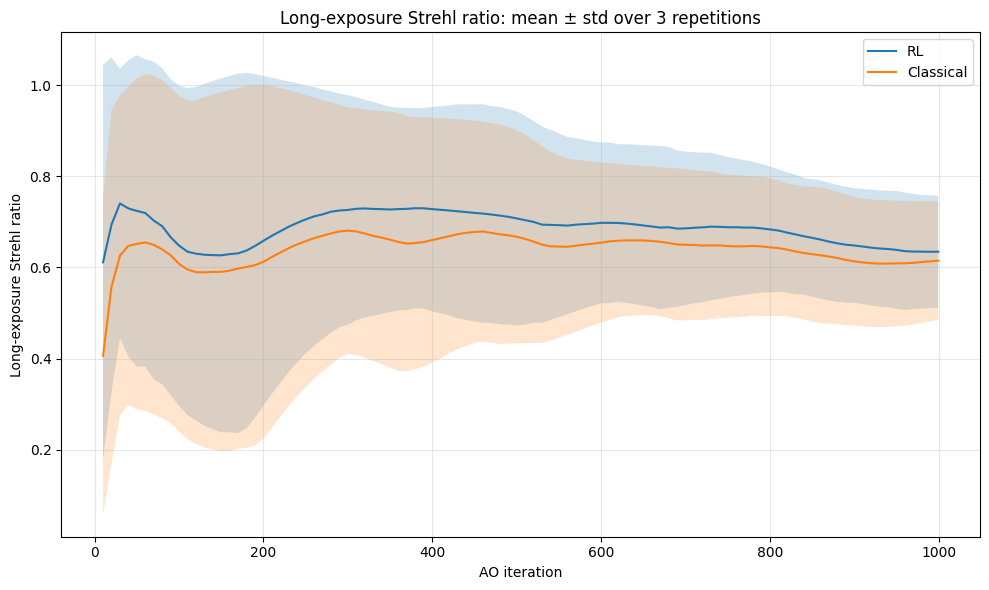

In [ ]:
IS_COLAB = False

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IS_COLAB = True
except Exception as e:
    print(f"Impossibile montare Google Drive ({type(e).__name__}: {e}). Salvo i risultati localmente.")
    IS_COLAB = False

if IS_COLAB:
    # Persistent but slower storage: use only for rare checkpoints/log shards and final artifacts.
    PERSISTENT_DIR = "/content/drive/MyDrive/RL_AO"
    # Fast ephemeral VM storage: use for video encoding and temporary files.
    WORK_DIR = "/content/RL_AO_work"
else:
    PERSISTENT_DIR = os.path.abspath("RL_AO_results")
    WORK_DIR = os.path.abspath("RL_AO_work")

os.makedirs(PERSISTENT_DIR, exist_ok=True)
os.makedirs(WORK_DIR, exist_ok=True)

args.checkpoint_dir = os.path.join(PERSISTENT_DIR, "checkpoints")

TRAINING_LOG_PATH = os.path.join(PERSISTENT_DIR, "training_log.csv",)

# Read/Write directories
POLICY_PATH = os.path.join(PERSISTENT_DIR, "sac_policy.pth",)


TEST_POLICY_PATH = ((os.path.splitext(POLICY_PATH)[0] + "_best.pth") if args.best_policy else POLICY_PATH)


# To resume after a Colab interruption:
if args.resume:
  RESUME_FROM = os.path.join(PERSISTENT_DIR, "checkpoints", "latest_checkpoint.pth")

  assert os.path.isfile(RESUME_FROM), \
    f"Checkpoint non found: {RESUME_FROM}"

  print("Checkpoint SAC correctly found!")

else:
  RESUME_FROM = None

# ------------------------------------------------------------------
# FINAL TESTS
# ------------------------------------------------------------------
# The deterministic RL controller and the classical controller are each
# evaluated on the same three atmospheric realisations (paired seeds).
# During the tests, LE Strehl is evaluated at every AO iteration so that
# mean, variance and standard deviation can be computed step by step.
# To avoid tripling the FFmpeg overhead, only the first repetition of each
# controller is recorded as video.

print("\n" + "=" * 72)
print("STARTING FINAL AO TESTS")
print("=" * 72)

NUM_TEST_REPEATS = args.num_test_repeats
TEST_BASE_SEED = 1234
RUN_CLASSICAL_REFERENCE = args.run_classical_reference


def aggregate_le_strehl_per_iteration(df):
    """Compute LE SR statistics across test repetitions at each AO iteration."""
    le_df = df[(df["type"] == "env") & np.isfinite(df["le_strehl"])].copy()

    return (le_df.groupby("episode_step", as_index=False).agg(
            le_strehl_mean=("le_strehl", "mean"),
            le_strehl_variance=("le_strehl", "var"),
            le_strehl_std=("le_strehl", "std"),))

# ------------------------------------------------------------------
# CLASSICAL TEST CACHE: one atomic CSV/metadata pair per repeat.
# Reuses the same atmospheric seeds across RL and classical comparisons.
# Cache is retained across reruns/Colab interruptions on persistent storage.
# ------------------------------------------------------------------
CLASSICAL_CACHE_VERSION = 1
CLASSICAL_CACHE_DIR = os.path.join(PERSISTENT_DIR, "classical_reference_cache")
os.makedirs(CLASSICAL_CACHE_DIR, exist_ok=True)

# Only parameters that can influence the classical AO simulation or its logged
# statistics. In particular, changing SAC --episodes never invalidates this cache.
_CLASSICAL_CONFIG_KEYS = (
    "wavelength_wfs", "telescope_diameter", "num_pupil_pixels",
    "num_actuators_across_pupil", "dm_oversampling", "rcond",
    "seeing", "outer_scale", "tau0", "prob_amp_coeff", "power_cutoff",
    "modulation_radius", "modulation_steps", "max_command",
    "gain", "leakage", "burn_in_iterations", "delta_t",
    "system_steps", "warm_up_steps", "le_strehl_every",
    "num_test_repeats", "save_log", "save_video",
    "video_every", "video_fps", "video_dpi",)

CLASSICAL_CACHE_CONFIG = {
    "version": CLASSICAL_CACHE_VERSION,
    "seed_base": TEST_BASE_SEED,
    "params": {key: getattr(args, key) for key in _CLASSICAL_CONFIG_KEYS},
    "video_path": str(args.video_path) if args.save_video and args.video_path else None,}


# ------------------------------------------------------------------
# CLASSICAL TEST: 3 repetitions
# ------------------------------------------------------------------
test_classical_df = None
test_classical_files = None
test_classical_le_per_iteration = None

if RUN_CLASSICAL_REFERENCE:
    classical_test_runs = []
    test_classical_env = None

    classical_video_local = os.path.join(WORK_DIR, "AO_without_RL.mp4",)

    for repeat_idx in range(NUM_TEST_REPEATS):
        # Reuse this exact atmospheric realisation later for the RL test.
        test_seed = TEST_BASE_SEED + repeat_idx

        cached = _load_cached_classical_repeat(repeat_idx)
        if cached is not None:
            print(f"[CACHE | CLASSICAL] Repeat {repeat_idx + 1}/{NUM_TEST_REPEATS} "
                  f"(seed={test_seed}): results loaded; simulation skipped.")
            if args.save_log:
                classical_test_runs.append(cached)
            continue

        print(
            f"\n[TEST | CLASSICAL] Repetition "
            f"{repeat_idx + 1}/{NUM_TEST_REPEATS}"
            f"(seed={test_seed}); saving result to persistent cache.")

        test_classical_env, repeat_logger = run_AO_system(
            POLICY_PATH,  # ignored when rl=False
            args,
            rl=False,
            layer_seed=test_seed,
            save_video=(args.save_video and repeat_idx == 0),
            video_path=classical_video_local,
        )

        if args.save_log:
          repeat_df = repeat_logger.dataframe().copy()
          repeat_df["repeat"] = repeat_idx + 1
          repeat_df["episode"] = repeat_idx + 1

          classical_test_runs.append(repeat_df)


        # Save the video to persistent storage BEFORE publishing cache metadata.
        if args.save_video and repeat_idx == 0:
            actual_video_path = args.video_path or classical_video_local
            if not os.path.isfile(actual_video_path):
                raise FileNotFoundError(f"Video classico mancante: {actual_video_path}")
            destination = os.path.join(PERSISTENT_DIR, "AO_without_RL.mp4")
            if os.path.abspath(actual_video_path) != os.path.abspath(destination):
                shutil.copy2(actual_video_path, destination)

        _save_cached_classical_repeat(repeat_idx, repeat_df)

    if args.save_log:
      test_classical_df = pd.concat(classical_test_runs, ignore_index=True,)

      # Save the complete raw statistics of all three classical repetitions.
      test_classical_files = RLLogger.save_statistics_bundle(
            test_classical_df,
            PERSISTENT_DIR,
            "test_classical",)

      # Mean, variance and std of LE SR at every iteration.
      test_classical_le_per_iteration = aggregate_le_strehl_per_iteration(test_classical_df)

      CLASSICAL_LE_STATS_PATH = os.path.join(PERSISTENT_DIR, "test_classical_LE_SR_per_iteration.csv",)

      RLLogger._atomic_csv_write(test_classical_le_per_iteration, CLASSICAL_LE_STATS_PATH,)

      print(f"[CACHE | CLASSICAL] Aggregated baseline results: {CLASSICAL_LE_STATS_PATH}")

# ------------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------------
if args.training:
    print("\n" + "=" * 72)
    print("STARTING SAC TRAINING / EVALUATION")
    print("=" * 72)

    sac = SAC(args)

    training_df = sac.train_eval(
        policy_path=POLICY_PATH,
        log_path=TRAINING_LOG_PATH,
        resume_from=RESUME_FROM,)

    if args.save_log:
      training_files = RLLogger.save_statistics_bundle(
          training_df,
          PERSISTENT_DIR,
          "training",)

# ------------------------------------------------------------------
# RL TEST: 3 repetitions
# ------------------------------------------------------------------
if not os.path.isfile(TEST_POLICY_PATH):
    raise FileNotFoundError(
        f"Test policy not found. To use --best_policy at least one evaluation RL "
        "must be/have been performed.")

rl_test_runs = []
test_rl_env = None

rl_video_local = os.path.join(WORK_DIR, "AO_with_RL.mp4",)

for repeat_idx in range(NUM_TEST_REPEATS):
    # Same seed as the matching classical repetition: paired comparison.
    #np.random.seed(TEST_BASE_SEED + repeat_idx)
    test_seed = TEST_BASE_SEED + repeat_idx
    print(f"\n[TEST | RL] Repetition {repeat_idx + 1}/{NUM_TEST_REPEATS}")

    test_rl_env, repeat_logger = run_AO_system(
        TEST_POLICY_PATH,
        args,
        rl = True,
        layer_seed = test_seed,
        save_video=(args.save_video and repeat_idx == 0),
        video_path=rl_video_local,)

    if args.save_log:
      repeat_df = repeat_logger.dataframe().copy()

      # Reuse the existing "episode" field to distinguish the 3 test repetitions.
      repeat_df["repeat"] = repeat_idx + 1
      repeat_df["episode"] = repeat_idx + 1

      rl_test_runs.append(repeat_df)

if args.save_log:
  test_rl_df = pd.concat(rl_test_runs, ignore_index=True,)

  # Save the complete raw statistics of all three RL repetitions.
  test_rl_files = RLLogger.save_statistics_bundle(test_rl_df, PERSISTENT_DIR, "test_RL",)

  # Mean, variance and std of LE SR at every iteration.
  test_rl_le_per_iteration = aggregate_le_strehl_per_iteration(test_rl_df)

  RL_LE_STATS_PATH = os.path.join(PERSISTENT_DIR, "test_RL_LE_SR_per_iteration.csv",)

  RLLogger._atomic_csv_write(test_rl_le_per_iteration, RL_LE_STATS_PATH,)

if args.save_video:
  if os.path.isfile(rl_video_local):
      shutil.copy2(rl_video_local, os.path.join(PERSISTENT_DIR, "AO_with_RL.mp4"),)

# ------------------------------------------------------------------
# LE STREHL COMPARISON PLOT
# ------------------------------------------------------------------
if args.save_log and test_classical_le_per_iteration is not None:
    fig, ax = plt.subplots(figsize=(10, 6))

    rl_x = test_rl_le_per_iteration["episode_step"].to_numpy()
    rl_mean = test_rl_le_per_iteration["le_strehl_mean"].to_numpy()
    rl_std = test_rl_le_per_iteration["le_strehl_std"].to_numpy()

    classical_x = test_classical_le_per_iteration["episode_step"].to_numpy()
    classical_mean = test_classical_le_per_iteration["le_strehl_mean"].to_numpy()
    classical_std = test_classical_le_per_iteration["le_strehl_std"].to_numpy()

    ax.plot(rl_x, rl_mean, label="RL",)
    ax.fill_between( rl_x, rl_mean - rl_std, rl_mean + rl_std, alpha=0.2,)

    ax.plot(classical_x, classical_mean, label="Classical",)
    ax.fill_between(classical_x, classical_mean - classical_std, classical_mean + classical_std, alpha=0.2,)

    ax.set_xlabel("AO iteration")
    ax.set_ylabel("Long-exposure Strehl ratio")
    ax.set_title(f"Long-exposure Strehl ratio: mean ± std over {NUM_TEST_REPEATS} repetitions")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()

    LE_PLOT_PATH = os.path.join(PERSISTENT_DIR, "LE_SR_RL_vs_classical_mean_std.png",)

    fig.savefig(LE_PLOT_PATH, dpi=200, bbox_inches="tight",)

    plt.show()
    plt.close(fig)